# Predicting Diabetes Risk from Self-Reported Health Indicators
### Traditional Machine Learning vs. Deep Learning on the CDC BRFSS 2015 Survey

**Author:** David Shumbusho · **Module:** Machine Learning — Summative Project

| Resource | Link |
|---|---|
| GitHub repository | https://github.com/Shumbusho43/SummativeML.git |
| Google Drive (raw data + saved models) | https://drive.google.com/drive/folders/1cvrziKSbJSD7fCHvzdFkXYAlizxkadWu?usp=sharing |
| Video presentation | _add link_ |

**Problem.** Roughly half of adults living with type 2 diabetes in sub-Saharan Africa are undiagnosed, largely because laboratory screening (HbA1c, fasting glucose) is costly and not always available. This notebook asks whether a short, *questionnaire-only* set of health indicators — the kind a community health worker could collect in a few minutes — is enough to flag people who should be referred for a blood test. We frame it as a **binary classification** problem: `0 = no diabetes`, `1 = prediabetes or diabetes`.

**Dataset.** *CDC Diabetes Health Indicators* (UCI Machine Learning Repository, id 891), derived from the 2015 U.S. Behavioral Risk Factor Surveillance System telephone survey: **253,680 respondents × 21 features**, with a categorical target. The raw file is downloaded at run time and is **not** committed to GitHub.

**Notebook map**
1. Setup & configuration
2. Data loading & data dictionary
3. Exploratory data analysis
4. Cleaning, feature engineering & data splits
5. Traditional ML (scikit-learn): baselines → model comparison → feature-engineering ablation → class-imbalance experiment → hyperparameter tuning → learning curves
6. Deep learning (TensorFlow/Keras + `tf.data`): Sequential baselines → regularised MLP → Functional wide-and-deep with embeddings → hyperparameter search
7. Head-to-head evaluation on the held-out test set (ROC, PR, confusion matrices, calibration, bootstrap CIs)
8. Error analysis
9. Saving the best models & Drive artefacts
10. Conclusions & limitations

## 1. Setup & configuration

All randomness is seeded with `SEED` so results are reproducible. `FAST_MODE = True` runs the whole notebook on a 25k-row sample with tiny search budgets (≈3 minutes) — useful for checking the pipeline end to end. The reported results use `FAST_MODE = False`.

The notebook runs as-is on Google Colab (scikit-learn and TensorFlow are pre-installed). Locally, install `requirements.txt` first.

In [1]:
import os, json, time, zipfile, shutil, urllib.request, platform, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, roc_curve, precision_recall_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
FAST_MODE = False          # True = quick smoke test on a sample; False = full experiment
keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow
tf.get_logger().setLevel("ERROR")  # hide harmless tf.function retracing notices

ROOT = Path.cwd()
DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR, DRIVE_DIR = (ROOT / d for d in
    ["data", "figures", "models", "results", "drive_upload"])
for d in [DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR, DRIVE_DIR]:
    d.mkdir(exist_ok=True)

# Experiment budgets
N_JOBS = -1
CV_FOLDS = 3
TUNE_SAMPLE = 8_000 if FAST_MODE else 80_000     # rows used inside RandomizedSearchCV
N_ITER = {"Logistic Regression": 2 if FAST_MODE else 10,
          "Random Forest": 2 if FAST_MODE else 8,
          "Hist Gradient Boosting": 3 if FAST_MODE else 20}
DL_EPOCHS = 3 if FAST_MODE else 40
DL_SEARCH_TRIALS = 2 if FAST_MODE else 8

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU is fine for tabular data)")

Python 3.13.16 | scikit-learn 1.6.1 | TensorFlow 2.21.0 | Keras 3.13.2
GPU: none (CPU is fine for tabular data)


A single plotting style is set once so every figure in the report is consistent. Colours come from a colour-blind-validated categorical palette, used in a fixed order: blue is always the *no diabetes* class and orange is always *diabetes/prediabetes*. Every figure is also saved to `figures/` for the written report.

In [2]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CLASS_NAMES = ["No diabetes", "Diabetes / prediabetes"]
CLASS_COLORS = [PALETTE[0], PALETTE[1]]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#a9a8a2",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 2. Data loading

The CSV is fetched directly from the UCI repository the first time the notebook runs and cached in `data/` (which is git-ignored). The `ID` column is a row index and carries no information, so it is dropped later.

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/891/data.csv"
RAW_CSV = DATA_DIR / "cdc_diabetes_health_indicators.csv"
TARGET = "Diabetes_binary"

def load_raw_data(url=DATA_URL, path=RAW_CSV):
    # Download once, then read from the local cache.
    if not path.exists():
        print(f"Downloading {url} ...")
        urllib.request.urlretrieve(url, path)
    return pd.read_csv(path)

raw = load_raw_data()
assert len(raw) >= 20_000, "Dataset must have at least 20,000 rows"
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 253,680 rows x 23 columns


,ID,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,1,40,1,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,1,0,0,0,0,25,1,0,0,1,...,0,1,3,0,0,0,0,7,6,1
2,2,0,1,1,1,28,0,0,0,0,...,1,1,5,30,30,1,0,9,4,8
3,3,0,1,0,1,27,0,0,0,1,...,1,0,2,0,0,0,0,11,3,6
4,4,0,1,1,1,24,0,0,0,1,...,1,0,2,3,0,0,0,11,5,4


### Data dictionary

| Feature | Type | Meaning |
|---|---|---|
| `Diabetes_binary` | target | 0 = no diabetes, 1 = prediabetes or diabetes |
| `HighBP`, `HighChol` | binary | Ever told by a health professional they have high blood pressure / high cholesterol |
| `CholCheck` | binary | Cholesterol check in the past 5 years |
| `BMI` | continuous | Body-mass index (kg/m²), computed from self-reported height and weight |
| `Smoker` | binary | Smoked ≥ 100 cigarettes in lifetime |
| `Stroke`, `HeartDiseaseorAttack` | binary | Ever had a stroke / coronary heart disease or myocardial infarction |
| `PhysActivity` | binary | Physical activity in the past 30 days (outside work) |
| `Fruits`, `Veggies` | binary | Eats fruit / vegetables at least once a day |
| `HvyAlcoholConsump` | binary | Heavy drinking (men > 14, women > 7 drinks per week) |
| `AnyHealthcare` | binary | Has any kind of health-care coverage |
| `NoDocbcCost` | binary | Needed a doctor in the past year but could not afford it |
| `GenHlth` | ordinal 1–5 | Self-rated general health (1 = excellent … 5 = poor) |
| `MentHlth`, `PhysHlth` | count 0–30 | Days of poor mental / physical health in the past 30 days |
| `DiffWalk` | binary | Serious difficulty walking or climbing stairs |
| `Sex` | binary | 0 = female, 1 = male |
| `Age` | ordinal 1–13 | 5-year age bands (1 = 18–24 … 9 = 60–64 … 13 = 80+) |
| `Education` | ordinal 1–6 | 1 = never attended school … 6 = college graduate |
| `Income` | ordinal 1–8 | 1 = < \$10k … 8 = ≥ \$75k per year |

## 3. Exploratory data analysis

### 3.1 Structure, missing values and duplicates
Every column is stored as an integer code. Below we check value ranges, missing values and exact duplicate rows. Duplicates matter here: with only 21 coarse features, many respondents give the same answers, and identical rows that land in both the training and test sets would inflate test scores.

In [4]:
features_raw = raw.drop(columns=["ID", TARGET])
summary = pd.DataFrame({
    "dtype": features_raw.dtypes.astype(str),
    "n_unique": features_raw.nunique(),
    "min": features_raw.min(),
    "max": features_raw.max(),
    "missing": features_raw.isna().sum(),
})
n_dup = raw.drop(columns=["ID"]).duplicated().sum()
print(f"Total missing values: {raw.isna().sum().sum()}")
print(f"Exact duplicate rows (ignoring ID): {n_dup:,} ({n_dup / len(raw):.1%})")
summary.T

Total missing values: 0
Exact duplicate rows (ignoring ID): 24,206 (9.5%)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,...,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
n_unique,2,2,2,84,2,2,2,2,2,2,...,2,2,5,31,31,2,2,13,6,8
min,0,0,0,12,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,1,1
max,1,1,1,98,1,1,1,1,1,1,...,1,1,5,30,30,1,1,13,6,8
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**Interpretation.** There are no missing values. Every feature is already integer-coded: 14 binary indicators, 4 ordinal scales and 3 counts (BMI and the two health-day variables). Two quality issues stand out. First, `BMI` reaches 98, which is implausible for almost all adults and almost certainly reflects self-report errors in height or weight. Second, 24,206 rows (9.5%) are exact duplicates. These are most likely real respondents who share a common answer profile (for example, young, healthy and with no conditions), not data-entry repeats. Even so, if kept they would let the model 'see' test rows during training.

### 3.2 Target distribution

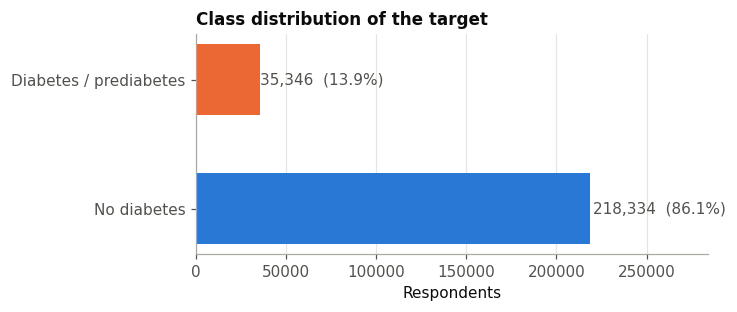

Imbalance ratio (negative:positive) = 6.2 : 1


In [5]:
counts = raw[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.6))
bars = ax.barh(CLASS_NAMES, counts.values, color=CLASS_COLORS, height=0.55)
for b, c in zip(bars, counts.values):
    ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2,
            f"{c:,}  ({c / counts.sum():.1%})", va="center", color=INK_2)
ax.set_xlabel("Respondents"); ax.set_xlim(0, counts.max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_title("Class distribution of the target")
save(fig, "01_class_distribution"); plt.show()
print(f"Imbalance ratio (negative:positive) = {counts[0] / counts[1]:.1f} : 1")

**Interpretation.** The target is imbalanced at roughly 6:1, with only 13.9% of respondents in the positive class. A classifier that always predicts "no diabetes" would reach about 86% accuracy while being clinically useless. This drives three design decisions: (1) threshold-free metrics, ROC-AUC and PR-AUC, are used for model selection; (2) class re-weighting is tested explicitly; and (3) the decision threshold is tuned on the validation set rather than left at 0.5.

### 3.3 Continuous features by class
`BMI`, `MentHlth` and `PhysHlth` are the only non-coded numeric features. Density histograms (each class normalised separately) show how their distributions shift between the classes.

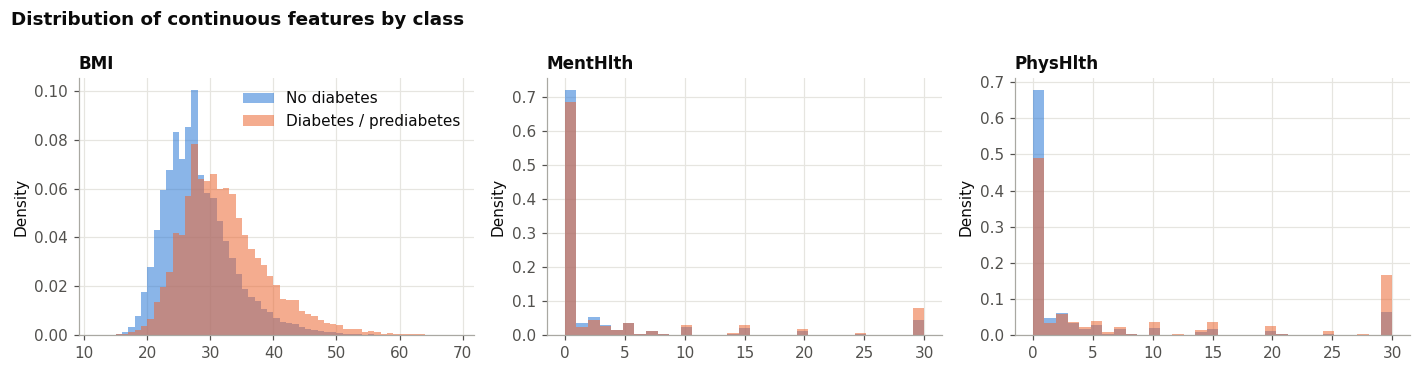

Diabetes_binary         0        1
BMI      count   218334.0  35346.0
         mean        27.8     31.9
         std          6.3      7.4
         min         12.0     13.0
         25%         24.0     27.0
         50%         27.0     31.0
         75%         31.0     35.0
         max         98.0     98.0
MentHlth count   218334.0  35346.0
         mean         3.0      4.5
         std          7.1      8.9
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      0.0
         75%          2.0      3.0
         max         30.0     30.0
PhysHlth count   218334.0  35346.0
         mean         3.6      8.0
         std          8.1     11.3
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      1.0
         75%          2.0     15.0
         max         30.0     30.0

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, bins in zip(axes, ["BMI", "MentHlth", "PhysHlth"], [np.arange(12, 70, 1), 31, 31]):
    for cls in [0, 1]:
        ax.hist(raw.loc[raw[TARGET] == cls, col], bins=bins, density=True, alpha=0.55,
                color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
    ax.set_title(col); ax.set_ylabel("Density")
axes[0].legend()
fig.suptitle("Distribution of continuous features by class", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "02_continuous_by_class"); plt.show()
raw.groupby(TARGET)[["BMI", "MentHlth", "PhysHlth"]].describe().T.round(1)

**Interpretation.** BMI is the clearest continuous separator: the median rises from 27 to 31 kg/m², and the positive class has a visibly heavier right tail. Both health-day variables are strongly zero-inflated (the median is 0 days for non-diabetic respondents). Their tails differ sharply, though: the 75th percentile of `PhysHlth` is 2 days for the negative class but 15 days for the positive class. `MentHlth` separates the classes much less. The skew and very different scales justify standardisation for the linear and neural models.

### 3.4 Prevalence across ordinal risk factors
For each ordinal variable we plot the share of respondents with diabetes/prediabetes at each level. This shows the risk gradient directly, and shows whether the relationship is monotonic (and so whether treating the codes as numbers is reasonable).

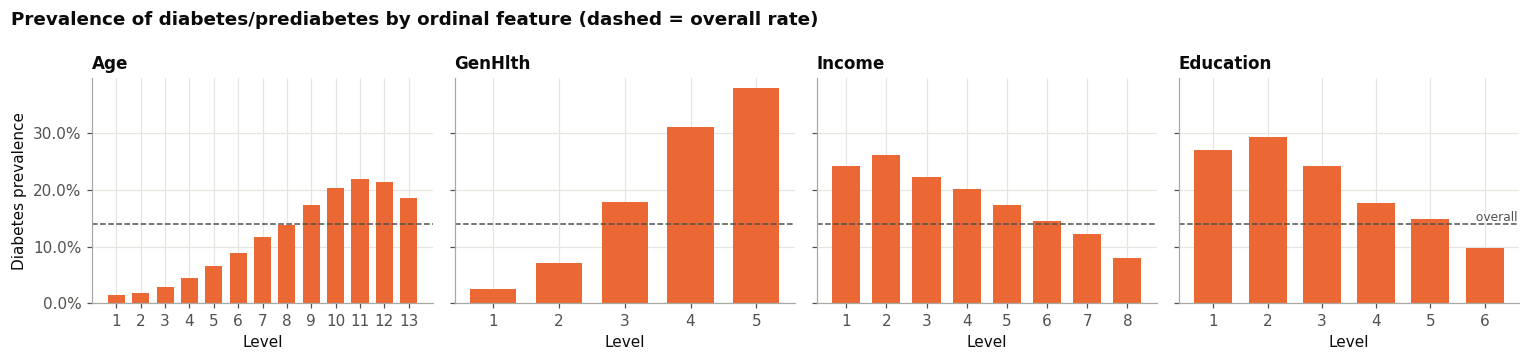

In [7]:
overall = raw[TARGET].mean()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3), sharey=True)
for ax, col in zip(axes, ["Age", "GenHlth", "Income", "Education"]):
    prev = raw.groupby(col)[TARGET].mean()
    ax.bar(prev.index.astype(str), prev.values, color=PALETTE[1], width=0.7)
    ax.axhline(overall, color=INK_2, lw=1, ls="--")
    ax.set_title(col); ax.set_xlabel("Level")
axes[0].set_ylabel("Diabetes prevalence")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[-1].text(5.6, overall, " overall", va="bottom", ha="right", color=INK_2, fontsize=8)
fig.suptitle("Prevalence of diabetes/prediabetes by ordinal feature (dashed = overall rate)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_prevalence_ordinal"); plt.show()

**Interpretation.** Self-rated general health (`GenHlth`) has the steepest gradient: prevalence climbs from about 2.5% among people reporting "excellent" health to almost 38% among those reporting "poor". Prevalence rises steadily with age up to band 11 (70–74) and then *falls* slightly in the oldest bands. This is consistent with survivorship bias, and it means the relationship is not strictly monotonic, which is one motivation for the embedding model in Section 6.5. Income and education show clear inverse socio-economic gradients. Note that education level 1 (never attended school) contains only 174 respondents, so its estimate is noisy.

### 3.5 Association of each feature with the target
The point-biserial correlation (Pearson correlation with a binary target) gives a quick, model-free ranking of univariate signal. It only captures linear, marginal association, so it is a starting point rather than a measure of importance.

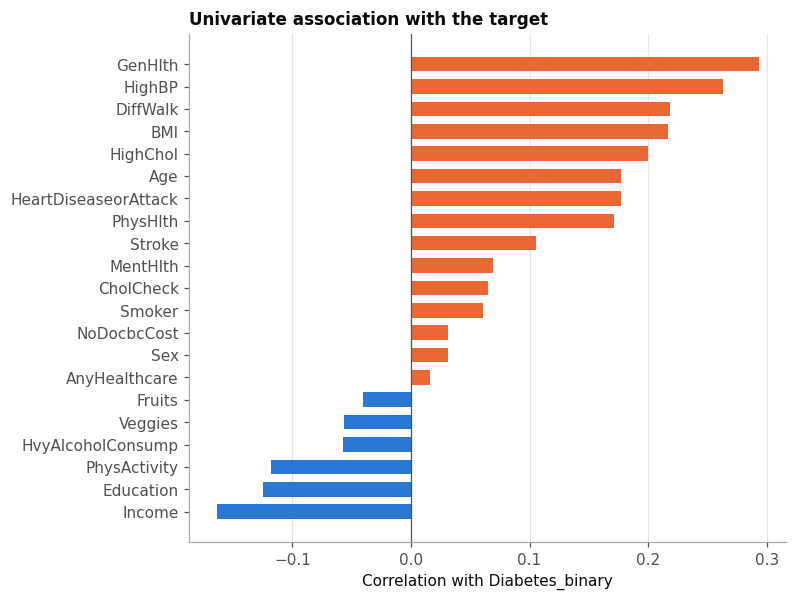

In [8]:
corr_target = raw.drop(columns=["ID"]).corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
colors = [PALETTE[1] if v > 0 else PALETTE[0] for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors, height=0.65)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Correlation with Diabetes_binary"); ax.grid(axis="y", visible=False)
ax.set_title("Univariate association with the target")
save(fig, "04_target_correlation"); plt.show()

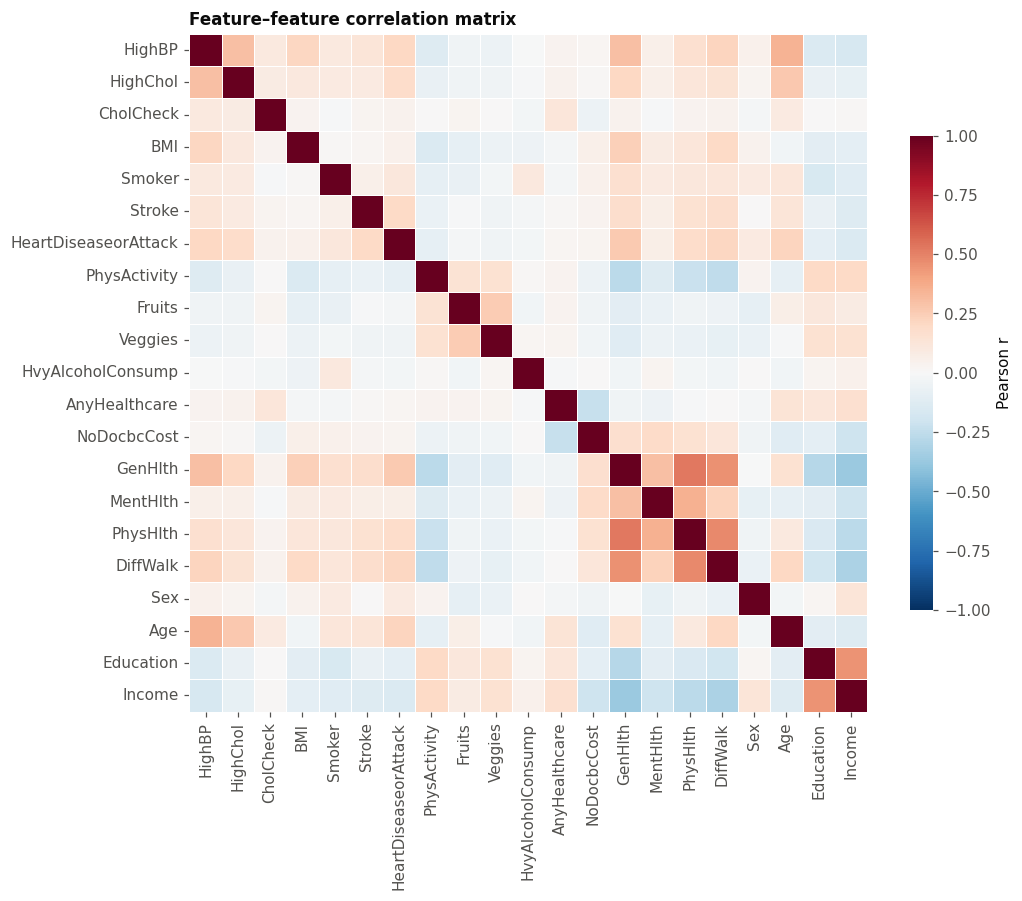

Strongest feature pairs (|r|):
GenHlth    PhysHlth    0.52
PhysHlth   DiffWalk    0.48
GenHlth    DiffWalk    0.46
Education  Income      0.45
GenHlth    Income      0.37
MentHlth   PhysHlth    0.35


In [9]:
corr = raw.drop(columns=["ID", TARGET]).corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.4,
            linecolor="white", cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Feature–feature correlation matrix")
save(fig, "05_feature_correlation"); plt.show()
top = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
       .abs().sort_values(ascending=False).head(6))
print("Strongest feature pairs (|r|):"); print(top.round(2).to_string())

**Interpretation.** `GenHlth` (r = 0.29), `HighBP` (0.26), `DiffWalk` and `BMI` (≈ 0.22) and `HighChol` (0.20) are the strongest univariate signals. `Income`, `Education` and `PhysActivity` are protective. No single feature correlates with the target above 0.3, which already suggests the task has a moderate ceiling: diabetes risk is spread thinly across many weak indicators. Feature–feature correlations peak at 0.52 (`GenHlth`–`PhysHlth`), so multicollinearity is modest and does not require dropping features. Regularised models handle what remains.

## 4. Cleaning, feature engineering & splits

### 4.1 Cleaning
* **Drop `ID`**: it is a row index with no predictive meaning.
* **Remove exact duplicates** *before* splitting, so the same record cannot appear in both training and test data (a subtle form of leakage).
* **No imputation is needed**: there are no missing values.
* **BMI outliers**: self-reported BMI runs up to 98, which is physiologically implausible for most respondents. Inside the feature-engineering step we clip BMI to the range [12, 60] instead of dropping rows.

In [10]:
df = raw.drop(columns=["ID"])
n_before, prev_before = len(df), df[TARGET].mean()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df):,} duplicates -> {len(df):,} unique rows")
print(f"Positive rate before: {prev_before:.2%} | after: {df[TARGET].mean():.2%}")

if FAST_MODE:
    df = df.sample(25_000, random_state=SEED).reset_index(drop=True)
    print("FAST_MODE: using a 25,000-row sample")

Removed 24,206 duplicates -> 229,474 unique rows
Positive rate before: 13.93% | after: 15.29%


**Interpretation.** After removing duplicates, 229,474 unique records remain, far above the 20,000-row minimum. Prevalence rises from 13.9% to 15.3% because the duplicated profiles are mostly *healthy, negative* respondents. This is worth reporting, because published results on the undeduplicated data are slightly optimistic for exactly this reason.

### 4.2 Feature engineering
The engineered features encode domain knowledge from the diabetes-risk literature (for example, the clinical risk scores FINDRISC and the ADA risk test, which combine age, adiposity, blood pressure and activity):

| New feature | Definition | Rationale |
|---|---|---|
| `CardioMetabolicLoad` | `HighBP + HighChol + Stroke + HeartDiseaseorAttack` | Clustering of metabolic-syndrome conditions |
| `LifestyleScore` | `PhysActivity + Fruits + Veggies − Smoker − HvyAlcoholConsump` | Composite healthy-behaviour index |
| `UnhealthyDays` | `MentHlth + PhysHlth` | CDC "healthy days" summary measure |
| `BMI_Category` | WHO bands: <18.5, 25, 30, 35, 40 | Non-linear obesity thresholds |
| `AgeBMI` | `Age × BMI` | Adiposity risk increases with age (interaction) |
| `SES_Index` | `Education + Income` | Socio-economic position |
| `CareBarrier` | no coverage **or** could not afford a doctor | Access to care |
| `PoorGenHlth` | `GenHlth ≥ 4` | Fair/poor self-rated health flag |
| `Obese` | `BMI ≥ 30` | Clinical obesity flag |

The feature logic lives in a small module, `diabetes_features.py`, written by the next cell. Keeping it outside the notebook means the saved scikit-learn pipeline can be loaded anywhere: `joblib` stores a *reference* to the function, so it must be importable. Because every transformation is row-wise and has no learned parameters, applying it cannot leak information between splits. The only fitted step, scaling, sits inside the pipeline and is fitted on training folds only.

In [11]:
%%writefile diabetes_features.py
"""Feature definitions shared by the notebook and the saved model pipelines."""
import numpy as np
import pandas as pd

BINARY_COLS = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
               "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
               "NoDocbcCost", "DiffWalk", "Sex"]
ORDINAL_COLS = ["GenHlth", "Age", "Education", "Income"]
CONT_COLS = ["BMI", "MentHlth", "PhysHlth"]
RAW_FEATURES = BINARY_COLS + ORDINAL_COLS + CONT_COLS

ENG_NUMERIC = ["CardioMetabolicLoad", "LifestyleScore", "UnhealthyDays", "BMI_Category",
               "AgeBMI", "SES_Index"]
ENG_BINARY = ["CareBarrier", "PoorGenHlth", "Obese"]


def engineer_features(X: pd.DataFrame) -> pd.DataFrame:
    """Row-wise, parameter-free feature engineering (safe to apply before or after splitting)."""
    X = X.copy()
    X["BMI"] = X["BMI"].clip(12, 60)
    X["CardioMetabolicLoad"] = X[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack"]].sum(axis=1)
    X["LifestyleScore"] = (X[["PhysActivity", "Fruits", "Veggies"]].sum(axis=1)
                           - X[["Smoker", "HvyAlcoholConsump"]].sum(axis=1))
    X["UnhealthyDays"] = X["MentHlth"] + X["PhysHlth"]
    X["BMI_Category"] = np.digitize(X["BMI"], [18.5, 25, 30, 35, 40])
    X["AgeBMI"] = X["Age"] * X["BMI"]
    X["SES_Index"] = X["Education"] + X["Income"]
    X["CareBarrier"] = ((X["AnyHealthcare"] == 0) | (X["NoDocbcCost"] == 1)).astype(int)
    X["PoorGenHlth"] = (X["GenHlth"] >= 4).astype(int)
    X["Obese"] = (X["BMI"] >= 30).astype(int)
    return X

Writing diabetes_features.py


In [12]:
import importlib, diabetes_features
importlib.reload(diabetes_features)
from diabetes_features import (BINARY_COLS, ORDINAL_COLS, CONT_COLS, RAW_FEATURES,
                               ENG_NUMERIC, ENG_BINARY, engineer_features)

def make_preprocessor(engineered=True):
    # Optional feature engineering, then scale numeric/ordinal columns and pass binaries through.
    num = CONT_COLS + ORDINAL_COLS + (ENG_NUMERIC if engineered else [])
    binary = BINARY_COLS + (ENG_BINARY if engineered else [])
    columns = ColumnTransformer([("num", StandardScaler(), num), ("bin", "passthrough", binary)],
                                verbose_feature_names_out=False)
    steps = [("features", FunctionTransformer(engineer_features))] if engineered else []
    return Pipeline(steps + [("columns", columns)])

def make_pipeline(model, engineered=True):
    return Pipeline([("prep", make_preprocessor(engineered)), ("model", model)])

eng_preview = engineer_features(df[RAW_FEATURES])
eng_preview[ENG_NUMERIC + ENG_BINARY].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CardioMetabolicLoad,229474.0,1.04,0.98,0.0,0.0,1.0,2.0,4.0
LifestyleScore,229474.0,1.61,1.09,-2.0,1.0,2.0,2.0,3.0
UnhealthyDays,229474.0,8.19,13.75,0.0,0.0,2.0,10.0,60.0
BMI_Category,229474.0,2.30,1.16,0.0,1.0,2.0,3.0,5.0
AgeBMI,229474.0,230.52,98.47,14.0,162.0,234.0,297.0,780.0
SES_Index,229474.0,10.87,2.67,2.0,9.0,11.0,13.0,14.0
CareBarrier,229474.0,0.13,0.33,0.0,0.0,0.0,0.0,1.0
PoorGenHlth,229474.0,0.19,0.39,0.0,0.0,0.0,0.0,1.0
Obese,229474.0,0.37,0.48,0.0,0.0,0.0,1.0,1.0


Do the engineered features separate the classes? Below is prevalence by `CardioMetabolicLoad` and by `BMI_Category`:

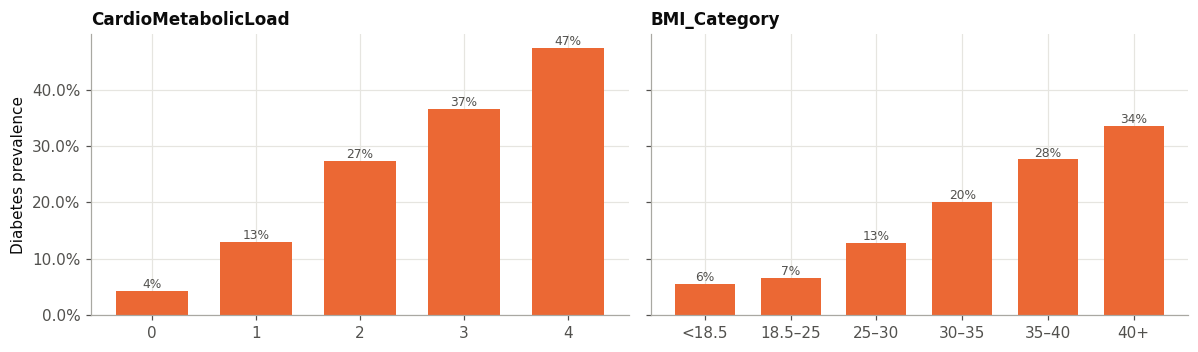

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, col, labels in zip(axes, ["CardioMetabolicLoad", "BMI_Category"],
                           [None, ["<18.5", "18.5–25", "25–30", "30–35", "35–40", "40+"]]):
    prev = df[TARGET].groupby(eng_preview[col]).mean()
    n = eng_preview[col].value_counts().sort_index()
    ax.bar(range(len(prev)), prev.values, color=PALETTE[1], width=0.7)
    ax.set_xticks(range(len(prev)), labels or prev.index.astype(str))
    for i, (p, k) in enumerate(zip(prev.values, n.values)):
        ax.text(i, p + 0.005, f"{p:.0%}", ha="center", color=INK_2, fontsize=8)
    ax.set_title(col)
axes[0].set_ylabel("Diabetes prevalence")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout(); save(fig, "06_engineered_features"); plt.show()

**Interpretation.** Both engineered features produce strong, monotonic risk gradients. Prevalence rises from 4.4% among respondents with no cardiometabolic conditions to 13%, 27%, 37% and 48% as the count goes from one to four. Across the WHO BMI bands it rises roughly six-fold, from 5.5% (underweight) to 33.6% (BMI ≥ 40). Each composite condenses several weak binary signals into one ordered variable that a linear model can use directly.

### 4.3 Train / validation / test split
We use a stratified **70 / 15 / 15** split.
* **Train**: used for model fitting and cross-validated hyperparameter search.
* **Validation**: used for early stopping in deep learning, for choosing between models, and for choosing the decision threshold.
* **Test**: touched **once**, in Section 7, for the final comparison.

The same split is shared by the ML and DL pipelines, so the comparison is like for like.

In [14]:
X = df[RAW_FEATURES]
y = df[TARGET].astype(int).values
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp,
                                                random_state=SEED)
pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
              "positive_rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).style.format({"rows": "{:,}", "positive_rate": "{:.2%}"})

,rows,positive_rate
train,"160,631",15.29%
validation,"34,421",15.29%
test,"34,422",15.30%


## 5. Traditional machine learning (scikit-learn)

Every model is wrapped in a `Pipeline` (preprocessing + estimator), so scaling is re-fitted inside each cross-validation fold and nothing leaks from the held-out fold.

**Metrics.** Because only ~14% of respondents are positive, accuracy is misleading: predicting "no diabetes" for everyone already scores ~86%. We therefore rank models by **ROC-AUC**, which is threshold-free and measures how well a model ranks positives above negatives. We also report **PR-AUC** (average precision), which is more sensitive to performance on the minority class, along with precision, recall, F1 and balanced accuracy at the default 0.5 threshold.

In [15]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1",
           "precision": "precision", "recall": "recall", "bal_acc": "balanced_accuracy"}
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

def run_cv(name, pipe, X, y, **extra):
    # Stratified k-fold CV; returns one summary row (mean of each metric, std of ROC-AUC).
    res = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=1)
    row = {"model": name, **extra}
    row.update({k: res[f"test_{k}"].mean() for k in SCORING})
    row["roc_auc_std"] = res["test_roc_auc"].std()
    row["fit_time_s"] = res["fit_time"].mean()
    print(f"{name:<34} ROC-AUC {row['roc_auc']:.4f} ± {row['roc_auc_std']:.4f}  "
          f"PR-AUC {row['pr_auc']:.4f}  ({row['fit_time_s']:.1f}s/fold)")
    return row

### 5.1 Experiment 1 — baselines and model comparison
We compare a **chance baseline** (a stratified dummy classifier) against five model families with different inductive biases: a probabilistic generative model (Gaussian Naïve Bayes), two linear models (Logistic Regression and a linear SVM), and two tree ensembles (bagging with Random Forest, and boosting with Histogram Gradient Boosting). Each model gets reasonable defaults and `class_weight="balanced"` where supported. A linear-kernel SVM is used because kernel SVMs scale as O(n²) and are impractical at 160k rows. Its scores are converted into probabilities with Platt scaling (`CalibratedClassifierCV`).

In [16]:
candidates = {
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Linear SVM (Platt-calibrated)": CalibratedClassifierCV(
        LinearSVC(C=1.0, class_weight="balanced", dual=False), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
        class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
comparison = pd.DataFrame([run_cv(n, make_pipeline(m), X_train, y_train) for n, m in candidates.items()])
comparison = comparison.sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparison.to_csv(RESULTS_DIR / "ml_model_comparison_cv.csv", index=False)
comparison.round(4)

Dummy (stratified)                 ROC-AUC 0.4999 ± 0.0011  PR-AUC 0.1529  (0.3s/fold)
Gaussian Naive Bayes               ROC-AUC 0.7804 ± 0.0016  PR-AUC 0.3687  (0.4s/fold)
Logistic Regression                ROC-AUC 0.8088 ± 0.0022  PR-AUC 0.4160  (2.3s/fold)
Linear SVM (Platt-calibrated)      ROC-AUC 0.8089 ± 0.0024  PR-AUC 0.4166  (2.7s/fold)
Random Forest                      ROC-AUC 0.8049 ± 0.0022  PR-AUC 0.4160  (29.9s/fold)
Hist Gradient Boosting             ROC-AUC 0.8141 ± 0.0021  PR-AUC 0.4313  (3.4s/fold)


,model,roc_auc,pr_auc,f1,precision,recall,bal_acc,roc_auc_std,fit_time_s
0,Hist Gradient Boosting,0.8141,0.4313,0.4500,0.3165,0.7786,0.7375,0.0021,3.4421
1,Linear SVM (Platt-calibrated),0.8089,0.4166,0.2463,0.5440,0.1592,0.5676,0.0024,2.6596
2,Logistic Regression,0.8088,0.4160,0.4516,0.3224,0.7538,0.7338,0.0022,2.2853
3,Random Forest,0.8049,0.4160,0.4595,0.3855,0.5686,0.7025,0.0022,29.8803
4,Gaussian Naive Bayes,0.7804,0.3687,0.4358,0.3356,0.6211,0.6996,0.0016,0.4070
5,Dummy (stratified),0.4999,0.1529,0.1525,0.1527,0.1524,0.4999,0.0011,0.2838


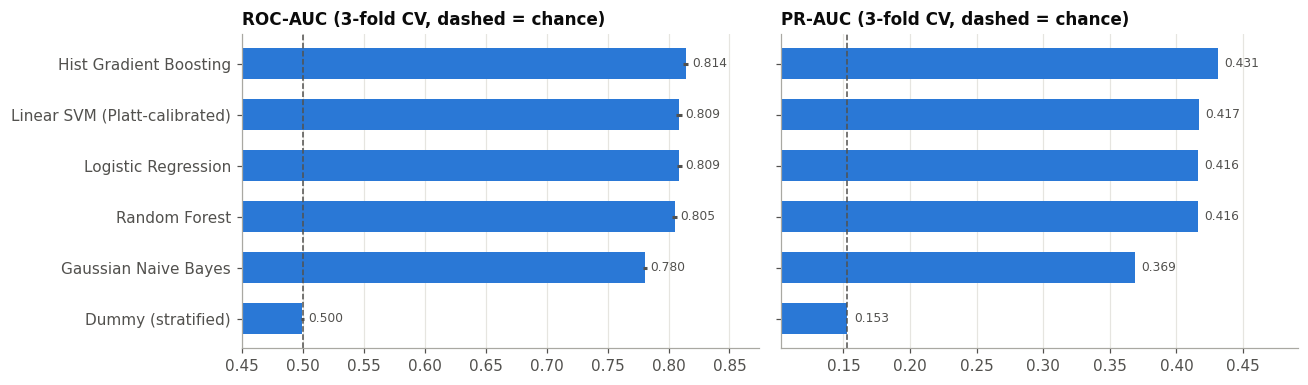

In [17]:
order = comparison.sort_values("roc_auc")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, metric, ref in zip(axes, ["roc_auc", "pr_auc"], [0.5, y_train.mean()]):
    ax.barh(order["model"], order[metric], color=PALETTE[0], height=0.6,
            xerr=order["roc_auc_std"] if metric == "roc_auc" else None, ecolor=INK_2)
    ax.axvline(ref, color=INK_2, ls="--", lw=1)
    for i, v in enumerate(order[metric]):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center", color=INK_2, fontsize=8)
    ax.set_xlim(ref - 0.05 if metric == "pr_auc" else 0.45, order[metric].max() + 0.06)
    ax.set_title(f"{metric.upper().replace('_', '-')} ({CV_FOLDS}-fold CV, dashed = chance)")
    ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "07_ml_model_comparison"); plt.show()

**Interpretation.** Every learned model beats chance by a wide margin, but the five real models fall within about 0.035 ROC-AUC of each other, and the top four are within 0.009. **Histogram Gradient Boosting** is best (CV ROC-AUC 0.814, PR-AUC 0.431), ahead of the linear models (≈ 0.809) and an untuned Random Forest (0.805). Gaussian Naïve Bayes trails (0.780) because its conditional-independence assumption is violated by correlated features such as `GenHlth`, `PhysHlth` and `DiffWalk`. The fold-to-fold standard deviation is small (≈ 0.002), so the ranking is stable. The threshold-dependent columns matter as much as AUC. With balanced weights, Logistic Regression and HGB catch about 75–78% of positives at 0.5. The Platt-calibrated SVM ranks just as well (AUC 0.809) but recalls only 16% at 0.5, because calibration undoes the class re-weighting and pushes probabilities back towards the 15% base rate. Its *ranking* is good, but its default threshold is wrong.

### 5.2 Experiment 2 — does feature engineering help?
An ablation study: the same two models are trained on the 21 raw features and on the raw + 9 engineered features. Logistic Regression should benefit most, because the engineered features add interactions and non-linear thresholds that a linear model cannot learn by itself. Tree ensembles can discover such splits on their own.

In [18]:
ablation = pd.DataFrame([
    run_cv(f"{name} | {'engineered' if eng else 'raw'}",
           make_pipeline(clone(candidates[name]), engineered=eng), X_train, y_train,
           base_model=name, features="engineered" if eng else "raw")
    for name in ["Logistic Regression", "Hist Gradient Boosting"] for eng in [False, True]])
ablation.to_csv(RESULTS_DIR / "ml_feature_ablation.csv", index=False)
ablation.pivot(index="base_model", columns="features", values=["roc_auc", "pr_auc"]).round(4)

Logistic Regression | raw          ROC-AUC 0.8063 ± 0.0021  PR-AUC 0.4038  (0.8s/fold)
Logistic Regression | engineered   ROC-AUC 0.8088 ± 0.0022  PR-AUC 0.4160  (2.2s/fold)
Hist Gradient Boosting | raw       ROC-AUC 0.8140 ± 0.0024  PR-AUC 0.4307  (2.4s/fold)
Hist Gradient Boosting | engineered ROC-AUC 0.8141 ± 0.0021  PR-AUC 0.4313  (3.5s/fold)


roc_auc             pr_auc        
features               engineered     raw engineered     raw
base_model                                                  
Hist Gradient Boosting     0.8141  0.8140     0.4313  0.4307
Logistic Regression        0.8088  0.8063     0.4160  0.4038

**Interpretation.** Feature engineering helps the linear model (ROC-AUC 0.806 → 0.809, PR-AUC 0.404 → 0.416). It makes no measurable difference to gradient boosting (0.8140 vs 0.8141). This is the expected pattern: boosted trees can already learn thresholds such as BMI ≥ 30 and interactions such as age × BMI from the raw features. Logistic Regression cannot, so the hand-crafted features partly close the gap between the two families. The engineered features are kept for all models because they never hurt and they make the linear model more interpretable.

### 5.3 Experiment 3 — handling class imbalance
We compare training **without** re-weighting against `class_weight="balanced"`, which multiplies the loss of each positive example by about 6×. Re-weighting changes *where* the model's probabilities fall, and so what the 0.5 threshold means. It should change ROC-AUC much less than it changes recall and precision.

In [19]:
imb_models = {
    "Logistic Regression": lambda cw: LogisticRegression(max_iter=2000, class_weight=cw),
    "Hist Gradient Boosting": lambda cw: HistGradientBoostingClassifier(class_weight=cw, random_state=SEED),
}
imbalance = pd.DataFrame([run_cv(f"{n} | weights={cw}", make_pipeline(f(cw)), X_train, y_train,
                                 base_model=n, class_weight=str(cw))
                          for n, f in imb_models.items() for cw in [None, "balanced"]])
imbalance.to_csv(RESULTS_DIR / "ml_imbalance_experiment.csv", index=False)
imbalance[["base_model", "class_weight", "roc_auc", "pr_auc", "precision", "recall", "f1", "bal_acc"]].round(4)

Logistic Regression | weights=None ROC-AUC 0.8086 ± 0.0023  PR-AUC 0.4179  (1.9s/fold)
Logistic Regression | weights=balanced ROC-AUC 0.8088 ± 0.0022  PR-AUC 0.4160  (2.4s/fold)
Hist Gradient Boosting | weights=None ROC-AUC 0.8138 ± 0.0021  PR-AUC 0.4299  (4.6s/fold)
Hist Gradient Boosting | weights=balanced ROC-AUC 0.8141 ± 0.0021  PR-AUC 0.4313  (6.1s/fold)


,base_model,class_weight,roc_auc,pr_auc,precision,recall,f1,bal_acc
0,Logistic Regression,None,0.8086,0.4179,0.5462,0.1611,0.2489,0.5685
1,Logistic Regression,balanced,0.8088,0.4160,0.3224,0.7538,0.4516,0.7338
2,Hist Gradient Boosting,None,0.8138,0.4299,0.5768,0.1526,0.2412,0.5662
3,Hist Gradient Boosting,balanced,0.8141,0.4313,0.3165,0.7786,0.4500,0.7375


**Interpretation.** Class weighting leaves ROC-AUC essentially unchanged (±0.0003). The ranking of patients does not change; only the scale of the predicted probabilities shifts. The effect at the 0.5 threshold, however, is dramatic: unweighted Logistic Regression catches only 16% of diabetic respondents, while the weighted model catches 75%, and balanced accuracy rises from 0.57 to 0.73. Without re-weighting, a 0.5 cut-off is unusable for screening. The same effect could be obtained by lowering the threshold, which is why Section 7 tunes the threshold explicitly instead of relying on either default.

### 5.4 Experiment 4 — hyperparameter tuning
`RandomizedSearchCV` samples from continuous and log-uniform distributions. Random search covers the important dimensions of the search space more efficiently than a grid of the same size (Bergstra & Bengio, 2012). To keep the search tractable we run it on a stratified **80k-row subsample** of the training set with 3-fold CV, optimising ROC-AUC. Each winning configuration is then **re-fitted on the full training set** and scored on the validation set, alongside its untuned default for comparison.

In [20]:
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNE_SAMPLE, stratify=y_train,
                                        random_state=SEED)
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", solver="liblinear"),
        {"model__C": loguniform(1e-3, 1e2), "model__penalty": ["l1", "l2"]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED),
        {"model__n_estimators": randint(150, 400), "model__max_depth": [8, 12, 16, 20, None],
         "model__min_samples_leaf": randint(1, 40), "model__max_features": ["sqrt", 0.3, 0.5]}),
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", early_stopping=True, random_state=SEED),
        {"model__learning_rate": loguniform(0.01, 0.3), "model__max_iter": randint(100, 800),
         "model__max_leaf_nodes": randint(8, 64), "model__min_samples_leaf": randint(20, 300),
         "model__l2_regularization": loguniform(1e-3, 10), "model__max_depth": [None, 3, 5, 8]}),
}
searches = {}
for name, (model, space) in search_spaces.items():
    t0 = time.time()
    searches[name] = RandomizedSearchCV(make_pipeline(model), space, n_iter=N_ITER[name], scoring="roc_auc",
                                        cv=CV, random_state=SEED, n_jobs=1, refit=False).fit(X_tune, y_tune)
    print(f"{name:<24} best CV ROC-AUC {searches[name].best_score_:.4f}  ({time.time() - t0:.0f}s)")
    print("   ", {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                  for k, v in searches[name].best_params_.items()})

Logistic Regression      best CV ROC-AUC 0.8110  (196s)
    {'C': np.float64(0.0746), 'penalty': 'l1'}
Random Forest            best CV ROC-AUC 0.8113  (615s)
    {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 33, 'n_estimators': 353}
Hist Gradient Boosting   best CV ROC-AUC 0.8145  (193s)
    {'l2_regularization': np.float64(3.7959), 'learning_rate': np.float64(0.0764), 'max_depth': 8, 'max_iter': 370, 'max_leaf_nodes': 15, 'min_samples_leaf': 234}


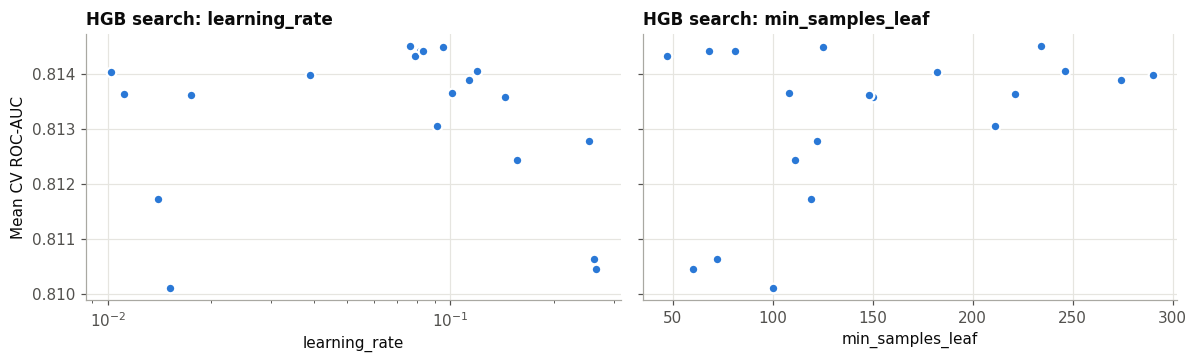

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
cvr = pd.DataFrame(searches["Hist Gradient Boosting"].cv_results_)
for ax, p in zip(axes, ["param_model__learning_rate", "param_model__min_samples_leaf"]):
    ax.scatter(cvr[p].astype(float), cvr["mean_test_score"], s=40, color=PALETTE[0],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_xlabel(p.replace("param_model__", "")); ax.set_title(f"HGB search: {p.replace('param_model__', '')}")
axes[0].set_xscale("log"); axes[0].set_ylabel("Mean CV ROC-AUC")
fig.tight_layout(); save(fig, "08_hgb_search"); plt.show()

Re-fit the default and tuned versions of each model on the full training set, then compare them on the validation set:

In [22]:
default_models = {"Logistic Regression": candidates["Logistic Regression"],
                  "Random Forest": candidates["Random Forest"],
                  "Hist Gradient Boosting": candidates["Hist Gradient Boosting"]}
tuned_pipes, tuning_rows = {}, []
for name, (model, _) in search_spaces.items():
    tuned = make_pipeline(clone(model)).set_params(**searches[name].best_params_)
    for label, pipe in [("default", make_pipeline(clone(default_models[name]))), ("tuned", tuned)]:
        t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
        p = pipe.predict_proba(X_val)[:, 1]
        tuning_rows.append({"model": name, "version": label, "val_roc_auc": roc_auc_score(y_val, p),
                            "val_pr_auc": average_precision_score(y_val, p), "fit_time_s": fit_s})
        if label == "tuned":
            tuned_pipes[name] = pipe
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(RESULTS_DIR / "ml_tuning_default_vs_tuned.csv", index=False)
tuning.pivot(index="model", columns="version", values=["val_roc_auc", "val_pr_auc"]).round(4)

val_roc_auc         val_pr_auc        
version                    default   tuned    default   tuned
model                                                        
Hist Gradient Boosting      0.8201  0.8203     0.4459  0.4459
Logistic Regression         0.8149  0.8150     0.4303  0.4304
Random Forest               0.8107  0.8176     0.4278  0.4408

In [23]:
best_ml_name = max(tuned_pipes, key=lambda n: tuning.query("model == @n and version == 'tuned'")["val_roc_auc"].item())
best_ml = tuned_pipes[best_ml_name]
print(f"Best traditional ML model (validation ROC-AUC): {best_ml_name}")

Best traditional ML model (validation ROC-AUC): Hist Gradient Boosting


**Interpretation.** Tuning gives a large gain only for Random Forest (validation ROC-AUC 0.811 → 0.818). The default forest grows very deep trees, and the search selected `min_samples_leaf ≈ 33` with `max_depth = 20`, a strong variance reduction. For HGB and Logistic Regression the gain is below 0.001: their defaults are already near-optimal for this problem, and the search scatter plot shows a broad plateau rather than a sharp optimum. HGB favoured moderate learning rates, shallow trees (15 leaves), large leaves and strong L2 regularisation, which also points to a *low-variance* problem. **Tuned HGB is the best traditional model** (validation ROC-AUC 0.820, PR-AUC 0.446).

### 5.5 Experiment 5 — learning curves
A learning curve trains the model on growing fractions of the training data and plots training vs. cross-validated ROC-AUC.
* A **large gap** that narrows as data grows means variance (overfitting).
* Both curves **plateauing low and close together** means bias: the features, not the amount of data, are the bottleneck.

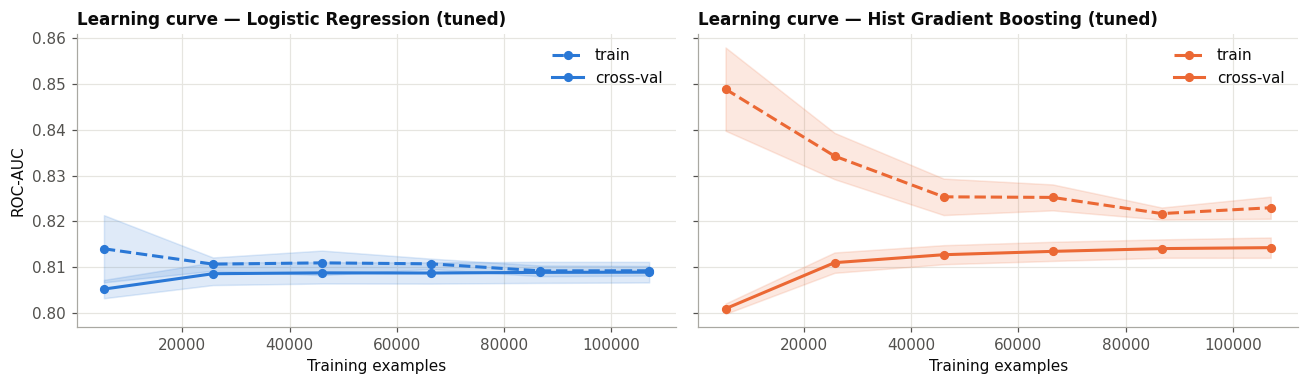

train_size  train_auc  cv_auc
model                                                  
Logistic Regression    0        5354     0.8140  0.8052
                       1       25700     0.8107  0.8086
                       2       46047     0.8110  0.8088
                       3       66393     0.8107  0.8087
                       4       86740     0.8092  0.8089
                       5      107087     0.8092  0.8089
Hist Gradient Boosting 0        5354     0.8488  0.8010
                       1       25700     0.8342  0.8110
                       2       46047     0.8254  0.8127
                       3       66393     0.8252  0.8135
                       4       86740     0.8217  0.8141
                       5      107087     0.8230  0.8143

In [24]:
def plot_learning_curve(pipe, title, ax, color):
    sizes, tr, te = learning_curve(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=1,
                                   train_sizes=np.linspace(0.05, 1.0, 6), shuffle=True, random_state=SEED)
    for scores, ls, lab in [(tr, "--", "train"), (te, "-", "cross-val")]:
        m, s = scores.mean(1), scores.std(1)
        ax.plot(sizes, m, ls=ls, color=color, marker="o", ms=5, label=lab)
        ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.15)
    ax.set_title(title); ax.set_xlabel("Training examples"); ax.legend()
    return pd.DataFrame({"train_size": sizes, "train_auc": tr.mean(1), "cv_auc": te.mean(1)})

lc_names = ["Logistic Regression", best_ml_name] if best_ml_name != "Logistic Regression" else ["Logistic Regression", "Hist Gradient Boosting"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
lc_tables = {n: plot_learning_curve(clone(tuned_pipes[n]), f"Learning curve — {n} (tuned)", ax, PALETTE[i])
             for i, (n, ax) in enumerate(zip(lc_names, axes))}
axes[0].set_ylabel("ROC-AUC")
fig.tight_layout(); save(fig, "09_ml_learning_curves"); plt.show()
pd.concat(lc_tables, names=["model"]).round(4)

**Interpretation.** The two learning curves tell different stories. For **Logistic Regression**, training and cross-validation AUC converge to about 0.809 by 25k examples and stay flat. This is classic high bias: more data will not help, only more expressive features or models will. For **HGB**, the train–CV gap shrinks from 0.048 at 5k examples to 0.009 at 107k, while CV AUC is still creeping up (0.8127 → 0.8143). The model is slightly variance-limited, but the curve is nearly flat, so doubling the data would add at most a few thousandths of AUC. Both curves point to the same conclusion: the bottleneck is the **information content of the 21 survey questions**, not sample size or model capacity.

## 6. Deep learning (TensorFlow / Keras)

### 6.1 Input pipeline with `tf.data`
The networks consume the same engineered and scaled features as the ML models. The preprocessing pipeline is fitted on the training split only. The data reaches Keras through `tf.data.Dataset` pipelines with these steps:
* `from_tensor_slices` creates the dataset from the in-memory arrays.
* `cache()` keeps the data in memory after the first epoch.
* `shuffle()` reshuffles each epoch, with a seed, for the training set only.
* `batch()` groups rows into mini-batches.
* `prefetch(AUTOTUNE)` overlaps data preparation with training.

Class imbalance is handled with Keras `class_weight`, using the same "balanced" formula as scikit-learn: w_c = n / (2·n_c).

In [25]:
dl_prep = make_preprocessor(engineered=True).fit(X_train)
DL_FEATURES = list(dl_prep.named_steps["columns"].get_feature_names_out())
Xtr_dl, Xva_dl, Xte_dl = (dl_prep.transform(d).astype("float32") for d in (X_train, X_val, X_test))
N_FEATURES = Xtr_dl.shape[1]

neg, pos = np.bincount(y_train)
CLASS_WEIGHT = {0: (neg + pos) / (2 * neg), 1: (neg + pos) / (2 * pos)}
print(f"{N_FEATURES} input features | class weights: {{0: {CLASS_WEIGHT[0]:.3f}, 1: {CLASS_WEIGHT[1]:.3f}}}")

def make_dataset(X, y, batch_size=512, training=False):
    # X may be an array or a dict of arrays (multi-input Functional models).
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32"))).cache()
    if training:
        ds = ds.shuffle(buffer_size=min(len(y), 50_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_dataset(Xtr_dl, y_train, training=True), make_dataset(Xva_dl, y_val)
xb, yb = next(iter(train_ds))
print("element_spec:", train_ds.element_spec)
print(f"one batch -> X {tuple(xb.shape)}, y {tuple(yb.shape)}, positives in batch: {int(yb.numpy().sum())}")

30 input features | class weights: {0: 0.590, 1: 3.269}
element_spec: (TensorSpec(shape=(None, 30), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
one batch -> X (512, 30), y (512,), positives in batch: 72


### 6.2 Shared model-building and training utilities
* `build_mlp` builds a configurable **Sequential** network. Its options are depth/width, dropout, L2 weight decay, batch normalisation, optimiser and learning rate.
* `train` fits a model with `EarlyStopping` (on validation ROC-AUC, restoring the best weights) and `ReduceLROnPlateau` (halving the learning rate when validation loss stalls).
* Every model reports ROC-AUC, PR-AUC, precision and recall at each epoch, so we get full training curves.

In [26]:
def dl_metrics():
    return [keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc"),
            keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]

def make_optimizer(name, lr):
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    return {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop}[name](learning_rate=lr)

def build_mlp(hidden=(64, 32), dropout=0.0, l2=0.0, batch_norm=False, lr=1e-3, optimizer="adam", name="mlp"):
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(N_FEATURES,)))
    for units in hidden:
        model.add(layers.Dense(units, use_bias=not batch_norm,
                               kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=make_optimizer(optimizer, lr), loss="binary_crossentropy", metrics=dl_metrics())
    return model

def train(model, train_ds, val_ds, epochs=DL_EPOCHS, class_weight=CLASS_WEIGHT, early_stopping=True, patience=6):
    cbs = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]
    if early_stopping:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience,
                                                 restore_best_weights=True))
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=class_weight,
                     callbacks=cbs, verbose=0)
    return pd.DataFrame(hist.history), time.time() - t0

dl_results, dl_histories, dl_models = [], {}, {}

def record(name, model, hist, secs, X_val_in, notes=""):
    p = model.predict(X_val_in, batch_size=4096, verbose=0).ravel()
    best_epoch = int(hist["val_auc"].idxmax()) + 1
    row = {"model": name, "val_roc_auc": roc_auc_score(y_val, p), "val_pr_auc": average_precision_score(y_val, p),
           "epochs_run": len(hist), "best_epoch": best_epoch, "params": model.count_params(),
           "train_time_s": secs, "notes": notes}
    dl_results.append(row); dl_histories[name] = hist; dl_models[name] = model
    print(f"{name:<34} val ROC-AUC {row['val_roc_auc']:.4f}  PR-AUC {row['val_pr_auc']:.4f}  "
          f"epochs {row['epochs_run']} (best {best_epoch})  {secs:.0f}s")

def plot_history(names, fname, title):
    metrics = [("loss", "Binary cross-entropy"), ("auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]
    fig, axes = plt.subplots(len(names), 3, figsize=(13, 2.9 * len(names)), squeeze=False)
    for r, n in enumerate(names):
        h = dl_histories[n]; ep = np.arange(1, len(h) + 1)
        for c, (m, lab) in enumerate(metrics):
            ax = axes[r, c]
            ax.plot(ep, h[m], color=PALETTE[0], label="train")
            ax.plot(ep, h[f"val_{m}"], color=PALETTE[1], label="validation")
            ax.set_title(lab, fontsize=10); ax.set_xlabel("Epoch")
            if r == 0 and c == 0: ax.legend()
        axes[r, 0].set_ylabel(textwrap.fill(n, 24), fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); save(fig, fname); plt.show()

### 6.3 Experiment DL-1 and DL-2 — Sequential baselines
* **DL-1**: a small 64→32 MLP trained for a fixed 30 epochs, with no class weights and no early stopping. It is a deliberately naïve reference that shows what an unregularised network does over a long run.
* **DL-2**: the same architecture with class weights and early stopping. This isolates the effect of those two training choices.

Model: "DL1_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

DL-1 MLP 64-32 (no weights, no ES) val ROC-AUC 0.8184  PR-AUC 0.4384  epochs 30 (best 12)  47s
DL-2 MLP 64-32 (+class weights, ES) val ROC-AUC 0.8193  PR-AUC 0.4433  epochs 13 (best 7)  22s


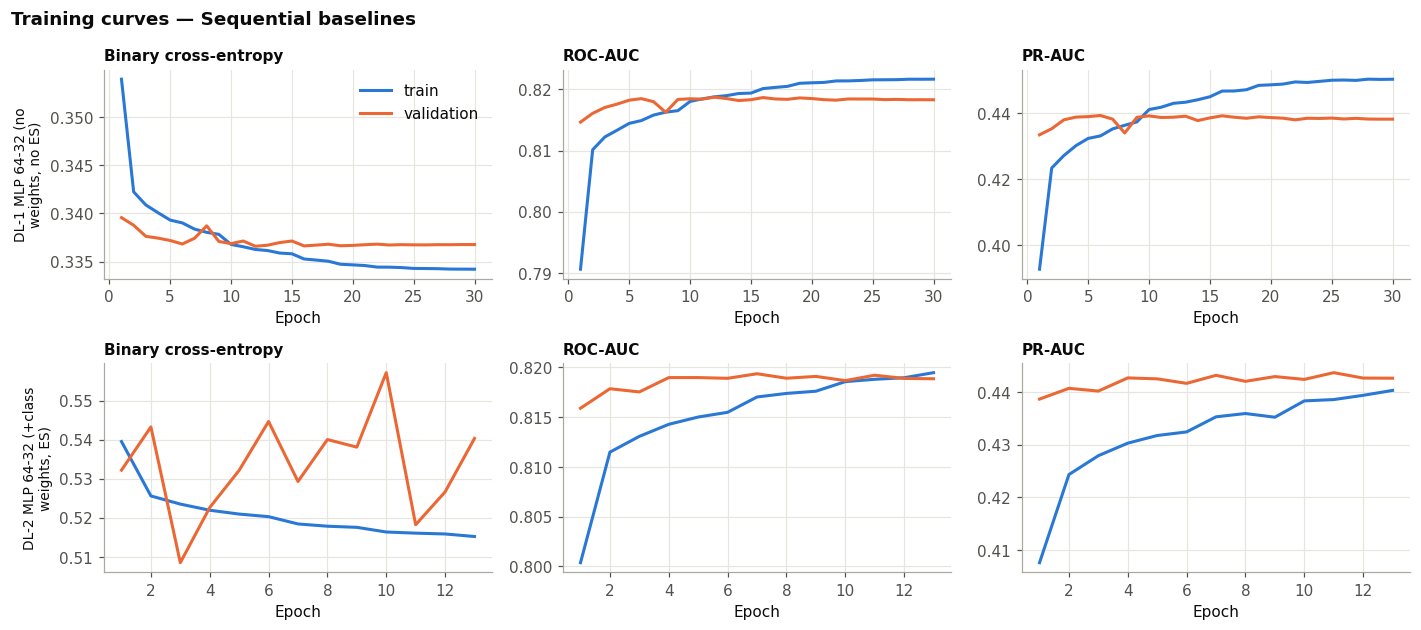

In [27]:
m = build_mlp(hidden=(64, 32), name="DL1_baseline")
m.summary()
h, s = train(m, train_ds, val_ds, epochs=min(30, DL_EPOCHS), class_weight=None, early_stopping=False)
record("DL-1 MLP 64-32 (no weights, no ES)", m, h, s, Xva_dl)

m = build_mlp(hidden=(64, 32), name="DL2_weighted")
h, s = train(m, train_ds, val_ds)
record("DL-2 MLP 64-32 (+class weights, ES)", m, h, s, Xva_dl)
plot_history(["DL-1 MLP 64-32 (no weights, no ES)", "DL-2 MLP 64-32 (+class weights, ES)"],
             "10_dl_baseline_curves", "Training curves — Sequential baselines")

**Interpretation.** **DL-1** (no weights, no early stopping) shows textbook overfitting dynamics. Validation loss bottoms out around epoch 6–12 while training loss keeps falling, and after about epoch 10 training AUC overtakes validation AUC and the gap widens. Because of the learning-rate decay, validation AUC plateaus rather than collapsing. **DL-2** (class weights + early stopping) stops after about 13 epochs and reaches a slightly higher validation ROC-AUC (≈ 0.819). Two quirks of the DL-2 curves are artefacts, not problems. First, its validation loss is *higher and noisier* than DL-1's because Keras applies `class_weight` only to the training loss: the weighted model deliberately inflates probabilities, which the unweighted validation BCE penalises. Second, validation AUC sits above training AUC because the training metric is averaged over an epoch of still-improving weights.

### 6.4 Experiment DL-3 — deeper, regularised Sequential network
A wider and deeper network (256→128→64) combined with three regularisers. **Batch normalisation** stabilises activations and allows faster learning rates. **Dropout (0.3)** prevents co-adaptation of units. **L2 weight decay (1e-4)** penalises large weights. Together they test whether extra capacity helps once overfitting is controlled.

Model: "DL3_regularised"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,497 (197.25 KB)

 Trainable params: 49,601 (193.75 KB)

 Non-trainable params: 896 (3.50 KB)

DL-3 MLP 256-128-64 (BN+Dropout+L2) val ROC-AUC 0.8197  PR-AUC 0.4447  epochs 14 (best 8)  83s


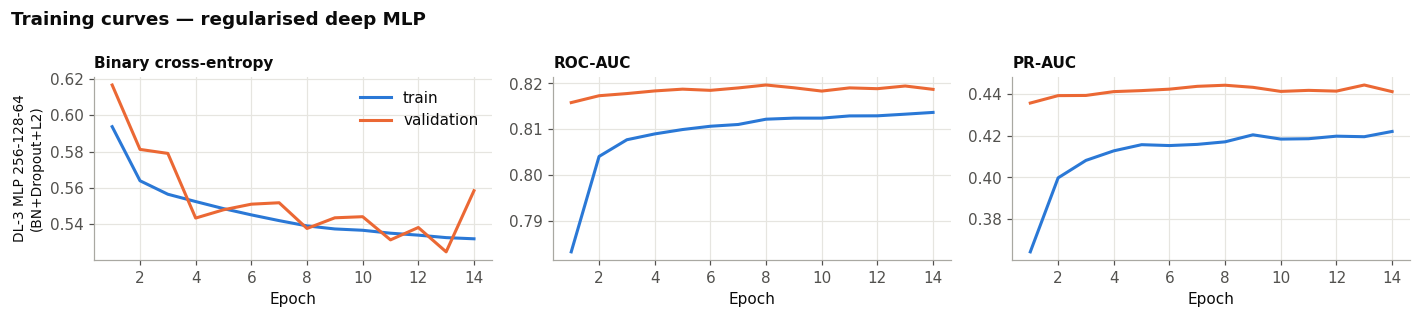

In [28]:
m = build_mlp(hidden=(256, 128, 64), dropout=0.3, l2=1e-4, batch_norm=True, name="DL3_regularised")
m.summary()
h, s = train(m, train_ds, val_ds)
record("DL-3 MLP 256-128-64 (BN+Dropout+L2)", m, h, s, Xva_dl)
plot_history(["DL-3 MLP 256-128-64 (BN+Dropout+L2)"], "11_dl_regularised_curves",
             "Training curves — regularised deep MLP")

**Interpretation.** Tripling the depth and multiplying parameters by about 12 (4k → 50k), with batch normalisation, dropout and L2 to keep it in check, gives only a marginal gain over DL-2 (≈ +0.0005 ROC-AUC) at roughly 8× the training time. The curves show no overfitting at all: training metrics stay *below* validation metrics throughout, because dropout is active during training. Early stopping triggers once validation AUC stops improving, not because of a growing gap. Extra capacity is therefore not what limits performance, which agrees with the ML learning curves.

### 6.5 Experiment DL-4 — Functional API: wide-and-deep network with embeddings
Inspired by Cheng et al. (2016), this **multi-input Functional model** treats the four ordinal variables (`Age`, `GenHlth`, `Income`, `Education`) as *categories* with learned 4-dimensional **embeddings**, instead of as scaled numbers. This lets the network learn non-monotonic effects per level.
* The **deep** path concatenates the embeddings with the other scaled features and passes them through a 128→64 MLP.
* The **wide** path is a linear model on the dense features plus one-hot ordinals. It can "memorise" simple main effects.
* The two logits are summed before the sigmoid.

The `tf.data` pipeline yields a *dictionary* of named inputs that matches the model's `Input` layers.

Model: "wide_and_deep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Age (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GenHlth             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Income (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Education           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Age_embedding       │ (None, 1, 4)      │         56 │ Age[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GenHlth_embedding   │ (None, 1, 4)      │         24 │ GenHlth[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Income_embedding    │ (None, 1, 4)      │         36 │ Income[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Education_embedding │ (None, 1, 4)      │         28 │ Education[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 26)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4)         │          0 │ Age_embedding[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4)         │          0 │ GenHlth_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 4)         │          0 │ Income_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 4)         │          0 │ Education_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_concat         │ (None, 42)        │          0 │ dense_features[0… │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │      5,504 │ deep_concat[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64)        │      8,256 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_encoding   │ (None, 14)        │          0 │ Age[0][0]       

 Total params: 14,800 (57.81 KB)

 Trainable params: 14,416 (56.31 KB)

 Non-trainable params: 384 (1.50 KB)

DL-4 Wide & Deep (Functional, embeddings) val ROC-AUC 0.8203  PR-AUC 0.4459  epochs 28 (best 22)  117s


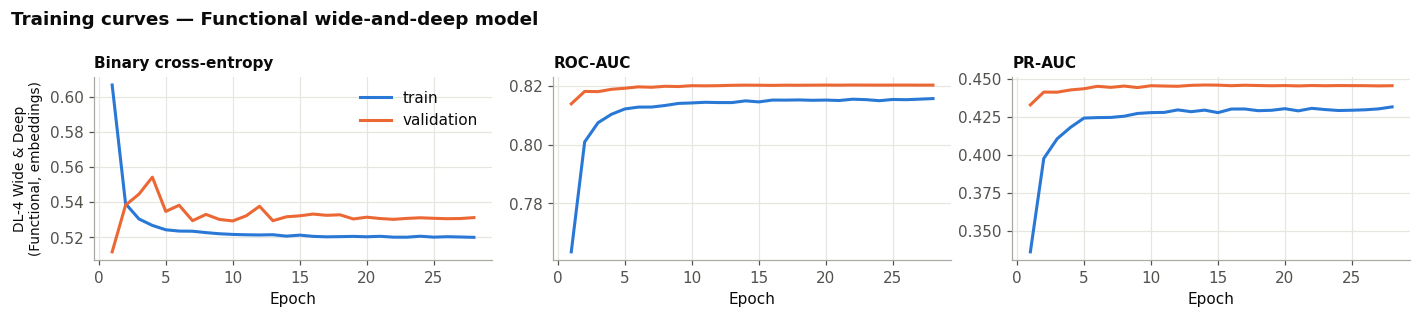

In [29]:
EMB_COLS = ["Age", "GenHlth", "Income", "Education"]
EMB_CARD = {"Age": 14, "GenHlth": 6, "Income": 9, "Education": 7}   # max code + 1

wd_prep = Pipeline([
    ("features", FunctionTransformer(engineer_features)),
    ("columns", ColumnTransformer([("num", StandardScaler(), CONT_COLS + ENG_NUMERIC),
                                   ("bin", "passthrough", BINARY_COLS + ENG_BINARY)])),
]).fit(X_train)

def to_wd_inputs(X):
    inputs = {"dense_features": wd_prep.transform(X).astype("float32")}
    inputs.update({c: X[c].to_numpy("int32").reshape(-1, 1) for c in EMB_COLS})
    return inputs

wd_train, wd_val, wd_test = to_wd_inputs(X_train), to_wd_inputs(X_val), to_wd_inputs(X_test)
N_DENSE = wd_train["dense_features"].shape[1]

def build_wide_deep(emb_dim=4, hidden=(128, 64), dropout=0.3, lr=1e-3):
    dense_in = keras.Input(shape=(N_DENSE,), name="dense_features")
    cat_in = {c: keras.Input(shape=(1,), dtype="int32", name=c) for c in EMB_COLS}
    embedded = [layers.Flatten()(layers.Embedding(EMB_CARD[c], emb_dim, name=f"{c}_embedding")(cat_in[c]))
                for c in EMB_COLS]
    one_hot = [layers.CategoryEncoding(num_tokens=EMB_CARD[c], output_mode="one_hot")(cat_in[c]) for c in EMB_COLS]

    deep = layers.Concatenate(name="deep_concat")([dense_in] + embedded)
    for units in hidden:
        deep = layers.Dense(units, activation="relu")(deep)
        deep = layers.BatchNormalization()(deep)
        deep = layers.Dropout(dropout)(deep)
    deep_logit = layers.Dense(1, name="deep_logit")(deep)
    wide_logit = layers.Dense(1, name="wide_logit")(layers.Concatenate(name="wide_concat")([dense_in] + one_hot))
    out = layers.Activation("sigmoid", name="probability")(layers.Add()([wide_logit, deep_logit]))

    model = keras.Model(inputs=[dense_in] + list(cat_in.values()), outputs=out, name="wide_and_deep")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=dl_metrics())
    return model

m = build_wide_deep()
m.summary()
h, s = train(m, make_dataset(wd_train, y_train, training=True), make_dataset(wd_val, y_val))
record("DL-4 Wide & Deep (Functional, embeddings)", m, h, s, wd_val)
plot_history(["DL-4 Wide & Deep (Functional, embeddings)"], "12_dl_widedeep_curves",
             "Training curves — Functional wide-and-deep model")

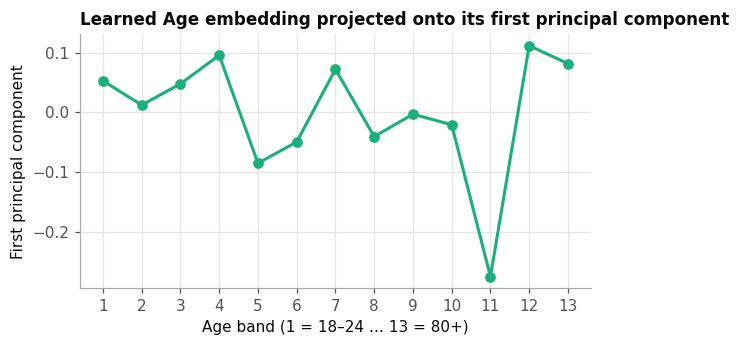

In [30]:
emb = m.get_layer("Age_embedding").get_weights()[0][1:]          # rows for codes 1..13
centered = emb - emb.mean(axis=0)
pc1 = centered @ np.linalg.svd(centered, full_matrices=False)[2][0]
pc1 *= np.sign(pc1[-1] - pc1[0])                                  # orient so older = higher
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, 14), pc1, marker="o", color=PALETTE[2])
ax.set_xticks(range(1, 14))
ax.set_xlabel("Age band (1 = 18–24 … 13 = 80+)"); ax.set_ylabel("First principal component")
ax.set_title("Learned Age embedding projected onto its first principal component")
save(fig, "13_age_embedding"); plt.show()

**Interpretation.** The Functional wide-and-deep model ties for the best validation ROC-AUC among the networks (≈ 0.820) with only 15k parameters, and it converges in fewer epochs than DL-3 because the wide (linear) path gives it a strong starting point. Treating the ordinal variables as learned categories is therefore *as good as*, but not better than, treating them as scaled numbers. The embedding plot explains why. Projected onto its first principal component, the learned Age embedding shows **no clear age ordering**: band 11 is an outlier and the rest are noise around zero. Age information reaches the model through other routes: the one-hot wide path, and the dense `AgeBMI` interaction. The deep embedding therefore has little left to learn, and its coordinates are not identifiable. The lesson is that embeddings pay off for high-cardinality categories. For a 13-level ordinal variable whose effect is nearly monotonic, a scaled numeric encoding is sufficient.

### 6.6 Experiment DL-5 — hyperparameter search
A random search over the Sequential MLP family. The search varies:
* architecture (width and depth)
* dropout rate
* learning rate
* **optimiser** (Adam, RMSprop, SGD with Nesterov momentum)
* batch size

Each trial uses early stopping on validation ROC-AUC. Configurations are sampled with a fixed seed, so the search is reproducible.

In [31]:
rng = np.random.default_rng(SEED)
space = {"hidden": [(64, 32), (128, 64), (256, 128, 64), (512, 256, 128)], "dropout": [0.1, 0.2, 0.3, 0.5],
         "lr": [3e-4, 1e-3, 3e-3], "optimizer": ["adam", "rmsprop", "sgd"], "batch_size": [256, 1024]}
search_rows = []
for t in range(DL_SEARCH_TRIALS):
    cfg = {k: v[rng.integers(len(v))] for k, v in space.items()}
    if cfg["optimizer"] == "sgd":
        cfg["lr"] = round(cfg["lr"] * 10, 6)   # SGD needs a larger step size than adaptive optimisers
    name = f"DL-5.{t + 1} search"
    m = build_mlp(hidden=cfg["hidden"], dropout=cfg["dropout"], l2=1e-5, batch_norm=True,
                  lr=cfg["lr"], optimizer=cfg["optimizer"], name=f"search_{t + 1}")
    h, s = train(m, make_dataset(Xtr_dl, y_train, cfg["batch_size"], training=True),
                 make_dataset(Xva_dl, y_val, cfg["batch_size"]), patience=4)
    record(name, m, h, s, Xva_dl, notes=str(cfg))
    search_rows.append({"trial": name, **{k: str(v) for k, v in cfg.items()}, **dl_results[-1]})
dl_search = pd.DataFrame(search_rows).sort_values("val_roc_auc", ascending=False)
dl_search.to_csv(RESULTS_DIR / "dl_hyperparameter_search.csv", index=False)
dl_search[["trial", "hidden", "dropout", "lr", "optimizer", "batch_size", "val_roc_auc", "val_pr_auc", "best_epoch"]].round(4)

DL-5.1 search                      val ROC-AUC 0.8186  PR-AUC 0.4420  epochs 24 (best 20)  90s
DL-5.2 search                      val ROC-AUC 0.8197  PR-AUC 0.4451  epochs 12 (best 8)  199s
DL-5.3 search                      val ROC-AUC 0.8173  PR-AUC 0.4385  epochs 21 (best 17)  119s
DL-5.4 search                      val ROC-AUC 0.8186  PR-AUC 0.4422  epochs 28 (best 24)  443s
DL-5.5 search                      val ROC-AUC 0.8161  PR-AUC 0.4388  epochs 38 (best 34)  196s
DL-5.6 search                      val ROC-AUC 0.8201  PR-AUC 0.4459  epochs 12 (best 8)  101s
DL-5.7 search                      val ROC-AUC 0.8203  PR-AUC 0.4438  epochs 18 (best 14)  51s
DL-5.8 search                      val ROC-AUC 0.8191  PR-AUC 0.4429  epochs 24 (best 20)  54s


,trial,hidden,dropout,lr,optimizer,batch_size,val_roc_auc,val_pr_auc,best_epoch
6,DL-5.7 search,"(128, 64)",0.1,0.0003,rmsprop,1024,0.8203,0.4438,14
5,DL-5.6 search,"(256, 128, 64)",0.2,0.003,rmsprop,256,0.8201,0.4459,8
1,DL-5.2 search,"(512, 256, 128)",0.1,0.003,adam,256,0.8197,0.4451,8
7,DL-5.8 search,"(64, 32)",0.5,0.003,adam,1024,0.8191,0.4429,20
0,DL-5.1 search,"(64, 32)",0.5,0.001,rmsprop,256,0.8186,0.4420,20
3,DL-5.4 search,"(512, 256, 128)",0.3,0.003,sgd,256,0.8186,0.4422,24
2,DL-5.3 search,"(256, 128, 64)",0.5,0.03,sgd,1024,0.8173,0.4385,17
4,DL-5.5 search,"(256, 128, 64)",0.2,0.003,sgd,1024,0.8161,0.4388,34


In [32]:
dl_table = pd.DataFrame(dl_results).sort_values("val_roc_auc", ascending=False).reset_index(drop=True)
dl_table.to_csv(RESULTS_DIR / "dl_all_experiments.csv", index=False)
best_dl_name = dl_table.loc[0, "model"]
best_dl = dl_models[best_dl_name]
best_dl_is_wd = best_dl_name.startswith("DL-4")
print(f"Best deep-learning model (validation ROC-AUC): {best_dl_name}")
dl_table.drop(columns="notes").round(4)

Best deep-learning model (validation ROC-AUC): DL-4 Wide & Deep (Functional, embeddings)


,model,val_roc_auc,val_pr_auc,epochs_run,best_epoch,params,train_time_s
0,"DL-4 Wide & Deep (Functional, embeddings)",0.8203,0.4459,28,22,14800,117.3462
1,DL-5.7 search,0.8203,0.4438,18,14,12865,51.4319
2,DL-5.6 search,0.8201,0.4459,12,8,50497,101.2845
3,DL-5.2 search,0.8197,0.4451,12,8,182913,199.1753
4,DL-3 MLP 256-128-64 (BN+Dropout+L2),0.8197,0.4447,14,8,50497,82.7011
5,"DL-2 MLP 64-32 (+class weights, ES)",0.8193,0.4433,13,7,4097,21.9904
6,DL-5.8 search,0.8191,0.4429,24,20,4385,54.4058
7,DL-5.1 search,0.8186,0.4420,24,20,4385,89.5953
8,DL-5.4 search,0.8186,0.4422,28,24,182913,442.5664
9,"DL-1 MLP 64-32 (no weights, no ES)",0.8184,0.4384,30,12,4097,47.0061


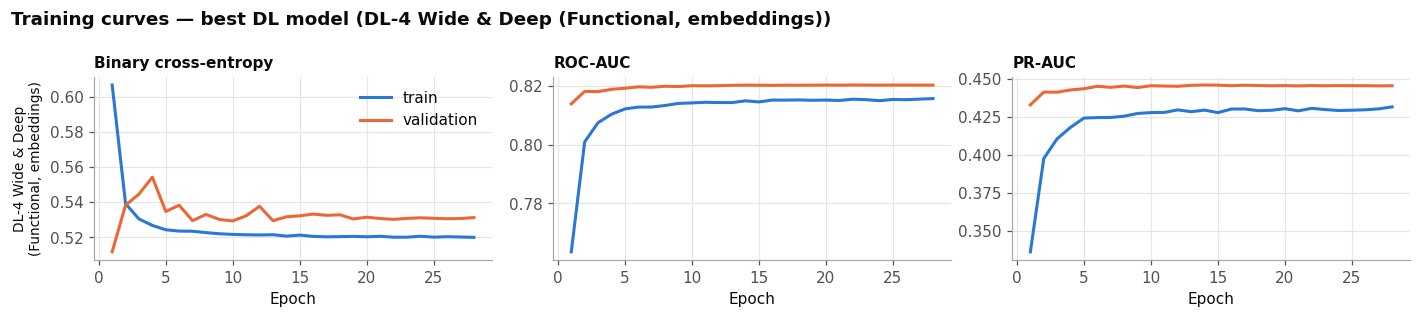

In [33]:
plot_history([best_dl_name], "14_dl_best_curves", f"Training curves — best DL model ({best_dl_name})")

**Interpretation.** Across all twelve DL runs, validation ROC-AUC spans only 0.816–0.820, a range smaller than the gap between Logistic Regression and HGB. The top three trials all use adaptive optimisers (RMSprop, Adam), and two of the three SGD-with-momentum trials are the worst in the search. Heavy dropout (0.5) slightly hurts, and very wide networks (512-256-128, 183k parameters) cost about 4× the training time with no benefit. The selected model trains in seconds on a CPU. The narrow spread is itself a finding: once a network is reasonably regularised and its imbalance handled, its architecture hardly matters on this data.

## 7. Final evaluation on the held-out test set

Four models go forward to the final comparison:
* the tuned **Logistic Regression**, as an interpretable reference
* the **best tuned traditional ML** model
* the **simple DL baseline** (DL-2)
* the **best deep-learning** model

**Threshold selection.** A screening tool rarely wants the default 0.5 cut-off. For each model we choose the threshold that **maximises F1 on the validation set**, then apply it unchanged to the test set. We also report the threshold reaching **≥ 80% recall**: a screening setting that accepts more false alarms in exchange for missing fewer cases.

**Uncertainty.** We report a 1,000-sample bootstrap 95% confidence interval for test ROC-AUC, plus a *paired* bootstrap for the difference between the best ML and best DL model.

In [34]:
def dl_predict(model, X, wide_deep=False):
    X_in = to_wd_inputs(X) if wide_deep else dl_prep.transform(X).astype("float32")
    return model.predict(X_in, batch_size=4096, verbose=0).ravel()

finalists = {"Logistic Regression (tuned)": lambda X: tuned_pipes["Logistic Regression"].predict_proba(X)[:, 1]}
if best_ml_name != "Logistic Regression":
    finalists[f"{best_ml_name} (tuned)"] = lambda X: best_ml.predict_proba(X)[:, 1]
finalists["DL-2 MLP baseline"] = lambda X: dl_predict(dl_models["DL-2 MLP 64-32 (+class weights, ES)"], X)
if best_dl_name != "DL-2 MLP 64-32 (+class weights, ES)":
    finalists[f"Best DL: {best_dl_name}"] = lambda X: dl_predict(best_dl, X, best_dl_is_wd)
BEST_ML_KEY = f"{best_ml_name} (tuned)"
BEST_DL_KEY = f"Best DL: {best_dl_name}" if f"Best DL: {best_dl_name}" in finalists else "DL-2 MLP baseline"

p_val = {n: f(X_val) for n, f in finalists.items()}
p_test = {n: f(X_test) for n, f in finalists.items()}

def f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])])

def recall_threshold(y, p, target=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    return float(thr[np.where(rec[:-1] >= target)[0][-1]])

def metrics_at(y, p, t):
    yhat = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
    return {"threshold": t, "accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat),
            "recall": recall_score(y, yhat), "specificity": tn / (tn + fp), "f1": f1_score(y, yhat),
            "bal_acc": balanced_accuracy_score(y, yhat)}

thresholds = {n: {"default_0.5": 0.5, "max_F1 (val)": f1_threshold(y_val, p_val[n]),
                  "recall>=0.80 (val)": recall_threshold(y_val, p_val[n])} for n in finalists}
rows = []
for n in finalists:
    base = {"model": n, "test_roc_auc": roc_auc_score(y_test, p_test[n]),
            "test_pr_auc": average_precision_score(y_test, p_test[n])}
    for tname, t in thresholds[n].items():
        rows.append({**base, "operating_point": tname, **metrics_at(y_test, p_test[n], t)})
final = pd.DataFrame(rows)
final.to_csv(RESULTS_DIR / "final_test_metrics.csv", index=False)
final.round(4)

,model,test_roc_auc,test_pr_auc,operating_point,threshold,accuracy,precision,recall,specificity,f1,bal_acc
0,Logistic Regression (tuned),0.8100,0.4174,default_0.5,0.5000,0.7168,0.3199,0.7561,0.7097,0.4496,0.7329
1,Logistic Regression (tuned),0.8100,0.4174,max_F1 (val),0.5848,0.7670,0.3570,0.6532,0.7876,0.4617,0.7204
2,Logistic Regression (tuned),0.8100,0.4174,recall>=0.80 (val),0.4638,0.6936,0.3071,0.7991,0.6745,0.4437,0.7368
3,Hist Gradient Boosting (tuned),0.8167,0.4376,default_0.5,0.5000,0.7050,0.3151,0.7913,0.6894,0.4507,0.7403
4,Hist Gradient Boosting (tuned),0.8167,0.4376,max_F1 (val),0.6150,0.7778,0.3706,0.6488,0.8010,0.4718,0.7249
5,Hist Gradient Boosting (tuned),0.8167,0.4376,recall>=0.80 (val),0.4950,0.7013,0.3126,0.7953,0.6843,0.4488,0.7398
6,DL-2 MLP baseline,0.8174,0.4373,default_0.5,0.5000,0.7058,0.3158,0.7918,0.6902,0.4515,0.7410
7,DL-2 MLP baseline,0.8174,0.4373,max_F1 (val),0.6453,0.7945,0.3897,0.6070,0.8283,0.4746,0.7177
8,DL-2 MLP baseline,0.8174,0.4373,recall>=0.80 (val),0.4965,0.7038,0.3149,0.7964,0.6871,0.4513,0.7417
9,"Best DL: DL-4 Wide & Deep (Functional, embeddi...",0.8172,0.4378,default_0.5,0.5000,0.7004,0.3128,0.8011,0.6822,0.4499,0.7417


In [35]:
def bootstrap_auc(y, p, n=1000, seed=SEED):
    r = np.random.default_rng(seed); idx = r.integers(0, len(y), (n, len(y)))
    return np.array([roc_auc_score(y[i], p[i]) for i in idx])

ci_rows = []
for n in finalists:
    b = bootstrap_auc(y_test, p_test[n])
    ci_rows.append({"model": n, "test_roc_auc": roc_auc_score(y_test, p_test[n]),
                    "ci_low": np.percentile(b, 2.5), "ci_high": np.percentile(b, 97.5)})
ci = pd.DataFrame(ci_rows); ci.to_csv(RESULTS_DIR / "final_auc_bootstrap_ci.csv", index=False)

r = np.random.default_rng(SEED); idx = r.integers(0, len(y_test), (1000, len(y_test)))
diff = np.array([roc_auc_score(y_test[i], p_test[BEST_ML_KEY][i]) - roc_auc_score(y_test[i], p_test[BEST_DL_KEY][i])
                 for i in idx])
print(f"Paired bootstrap: AUC({BEST_ML_KEY}) - AUC({BEST_DL_KEY}) = {diff.mean():+.4f} "
      f"[95% CI {np.percentile(diff, 2.5):+.4f}, {np.percentile(diff, 97.5):+.4f}]; "
      f"P(diff <= 0) = {(diff <= 0).mean():.3f}")
ci.round(4)

Paired bootstrap: AUC(Hist Gradient Boosting (tuned)) - AUC(Best DL: DL-4 Wide & Deep (Functional, embeddings)) = -0.0005 [95% CI -0.0016, +0.0005]; P(diff <= 0) = 0.822


,model,test_roc_auc,ci_low,ci_high
0,Logistic Regression (tuned),0.8100,0.8042,0.8158
1,Hist Gradient Boosting (tuned),0.8167,0.8111,0.8225
2,DL-2 MLP baseline,0.8174,0.8118,0.8232
3,"Best DL: DL-4 Wide & Deep (Functional, embeddi...",0.8172,0.8117,0.8231


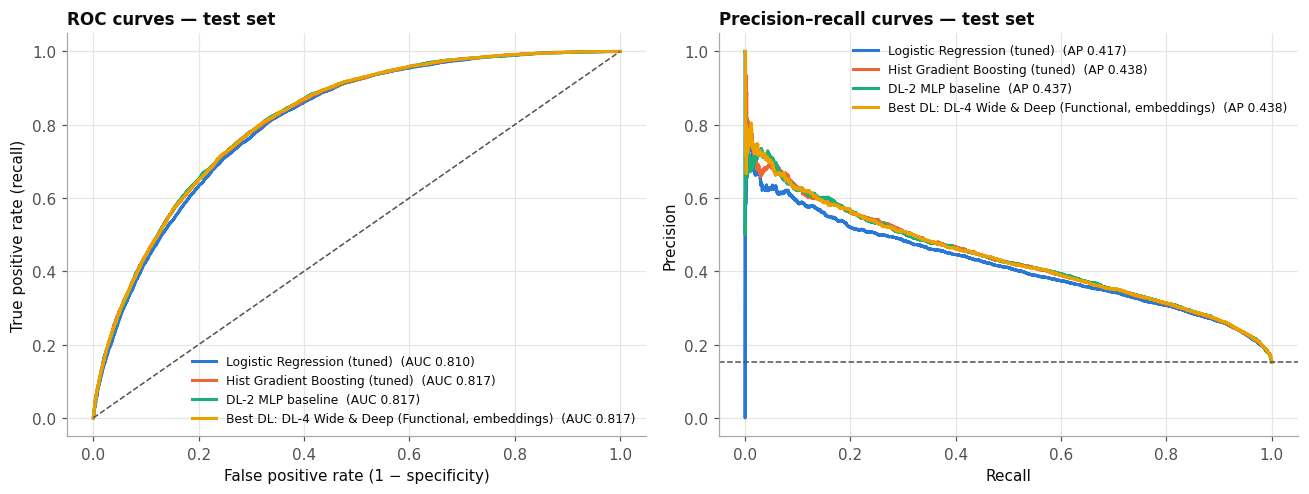

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for i, n in enumerate(finalists):
    fpr, tpr, _ = roc_curve(y_test, p_test[n])
    axes[0].plot(fpr, tpr, color=PALETTE[i], label=f"{n}  (AUC {roc_auc_score(y_test, p_test[n]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p_test[n])
    axes[1].plot(rec, prec, color=PALETTE[i], label=f"{n}  (AP {average_precision_score(y_test, p_test[n]):.3f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1)
axes[0].set(xlabel="False positive rate (1 − specificity)", ylabel="True positive rate (recall)", title="ROC curves — test set")
axes[1].axhline(y_test.mean(), color=INK_2, ls="--", lw=1)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves — test set")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout(); save(fig, "15_roc_pr_curves"); plt.show()

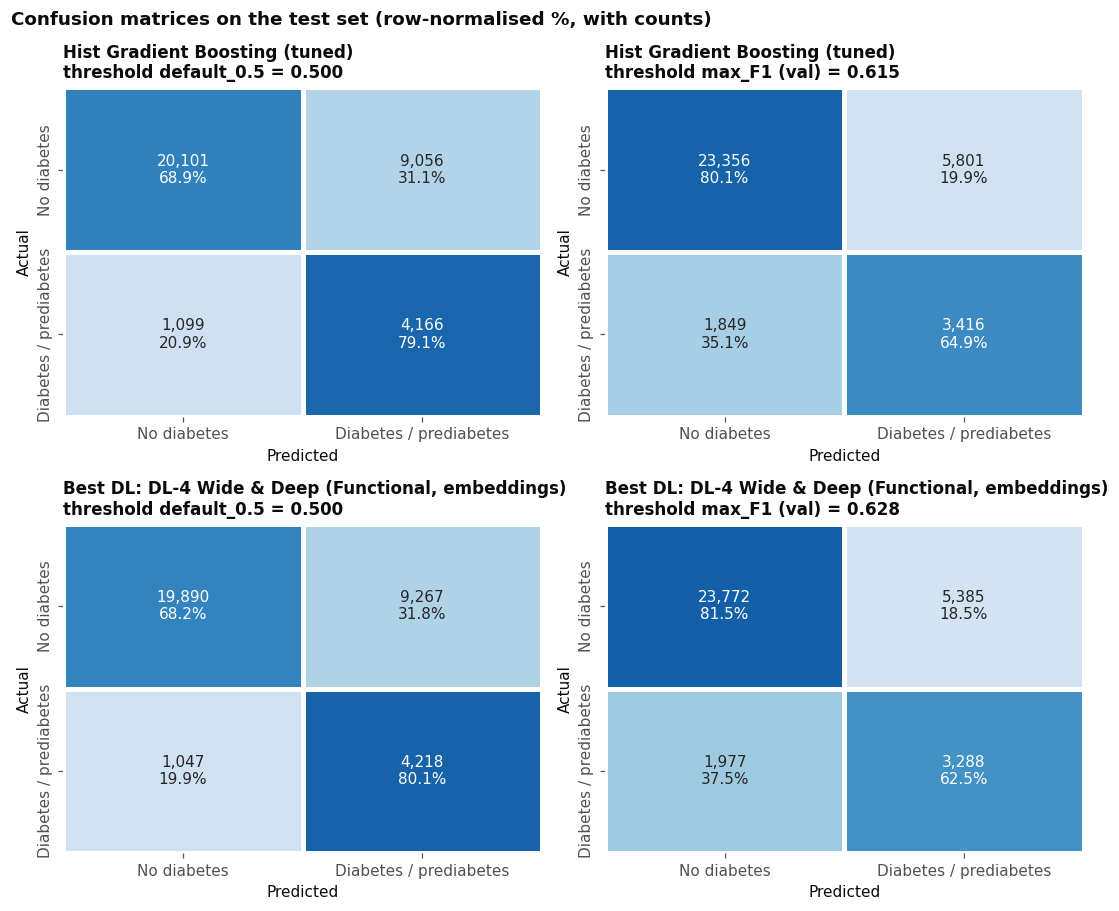

In [37]:
show = [BEST_ML_KEY, BEST_DL_KEY]
fig, axes = plt.subplots(2, 2, figsize=(10, 8.4))
for r, n in enumerate(show):
    for c, tname in enumerate(["default_0.5", "max_F1 (val)"]):
        t = thresholds[n][tname]; cm = confusion_matrix(y_test, (p_test[n] >= t).astype(int))
        ax = axes[r, c]; pct = cm / cm.sum(axis=1, keepdims=True)
        sns.heatmap(pct, annot=np.array([[f"{cm[i, j]:,}\n{pct[i, j]:.1%}" for j in range(2)] for i in range(2)]),
                    fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=2, linecolor="white",
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, annot_kws={"fontsize": 10})
        ax.set(xlabel="Predicted", ylabel="Actual", title=f"{n}\nthreshold {tname} = {t:.3f}")
        ax.title.set_fontsize(9)
fig.suptitle("Confusion matrices on the test set (row-normalised %, with counts)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "16_confusion_matrices"); plt.show()

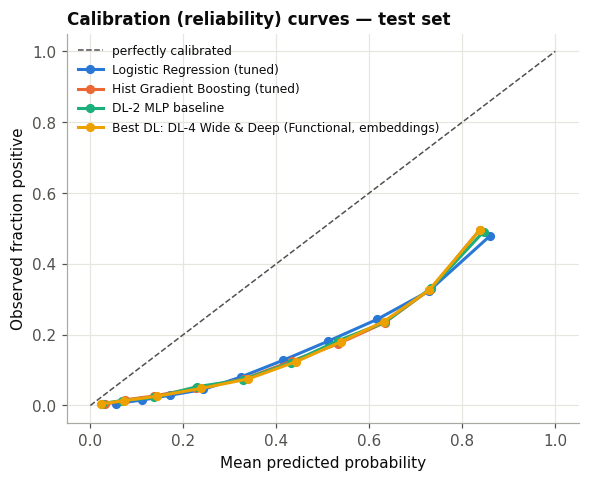

In [38]:
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1, label="perfectly calibrated")
for i, n in enumerate(finalists):
    frac, mean_pred = calibration_curve(y_test, p_test[n], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", ms=5, color=PALETTE[i], label=n)
ax.set(xlabel="Mean predicted probability", ylabel="Observed fraction positive", title="Calibration (reliability) curves — test set")
ax.legend(fontsize=8); save(fig, "17_calibration"); plt.show()

**Interpretation.** On the untouched test set (34,422 respondents), tuned HGB and the neural networks are **statistically indistinguishable**: test ROC-AUC ≈ 0.817, with overlapping 95% bootstrap intervals of about ±0.006. The paired bootstrap difference between the best ML and best DL model is centred on zero, and its confidence interval comfortably includes zero. All of them beat tuned Logistic Regression (0.810) by a small but reliable margin; its interval only just overlaps theirs, and its PR curve sits visibly lower at low recall, where the top-ranked patients are. The ROC curves almost coincide. The **operating point** matters far more than the model. At the default 0.5 threshold, HGB recalls 79% of diabetic respondents at 69% specificity. At the F1-optimal threshold chosen on validation, recall drops to 65%, specificity rises to 80% and precision to 37%. For a screening tool, where a missed case costs more than a confirmatory blood test, the recall-≥-80% operating point is the more defensible choice: roughly 4 in 5 cases are caught, at the cost of about 2 referrals in 3 being false alarms. The calibration plot reveals the price of class weighting: every model **over-predicts** risk (a predicted 0.6 corresponds to an observed rate of about 0.23). Probabilities would need recalibration, for example with Platt or isotonic scaling, before they could be shown to patients as risks. Rankings and thresholds are unaffected.

## 8. Error analysis

We examine the errors of the overall best model at its F1-optimal threshold. We ask three questions:
1. **Who is misclassified?** We profile false negatives and false positives against the correctly classified groups.
2. **Is performance uniform across sub-populations?** We compute recall and precision by age, sex, income and BMI band. This is an equity check that matters for any screening tool.
3. **What drives the model?** We compute permutation importance on the validation set.

In [39]:
best_overall = max([BEST_ML_KEY, BEST_DL_KEY], key=lambda n: roc_auc_score(y_val, p_val[n]))
t_best = thresholds[best_overall]["max_F1 (val)"]
pred = (p_test[best_overall] >= t_best).astype(int)
ea = X_test.copy()
ea["y"], ea["p"], ea["pred"] = y_test, p_test[best_overall], pred
ea["outcome"] = np.select([(ea.y == 1) & (ea.pred == 1), (ea.y == 0) & (ea.pred == 1),
                           (ea.y == 1) & (ea.pred == 0)], ["TP", "FP", "FN"], "TN")
print(f"Error analysis for: {best_overall}  (threshold {t_best:.3f})")
print(ea["outcome"].value_counts().to_string())
profile_cols = ["BMI", "Age", "GenHlth", "HighBP", "HighChol", "DiffWalk", "PhysHlth", "Income", "HeartDiseaseorAttack"]
profile = ea.groupby("outcome")[profile_cols].mean().loc[["TP", "FN", "FP", "TN"]]
profile.to_csv(RESULTS_DIR / "error_profile.csv")
profile.round(2)

Error analysis for: Best DL: DL-4 Wide & Deep (Functional, embeddings)  (threshold 0.628)
outcome
TN    23772
FP     5385
TP     3288
FN     1977


,BMI,Age,GenHlth,HighBP,HighChol,DiffWalk,PhysHlth,Income,HeartDiseaseorAttack
outcome,,,,,,,,,
TP,34.15,9.65,3.69,0.90,0.78,0.50,10.23,4.77,0.30
FN,28.63,8.87,2.64,0.53,0.48,0.16,4.11,5.84,0.08
FP,32.69,9.75,3.50,0.87,0.74,0.43,9.03,4.99,0.26
TN,27.04,7.47,2.26,0.30,0.32,0.09,3.04,6.23,0.04


**Interpretation.** The error profile is informative. **False negatives look like true negatives**: compared with correctly detected cases, missed diabetics have a lower BMI (≈ 29 vs 34), are roughly half as likely to report high blood pressure or cholesterol, rarely report difficulty walking, rate their general health better (≈ 2.7 vs 3.7) and earn more. In other words, they are diabetic people *without the usual comorbidity footprint*. Many are probably early-stage or prediabetic, and no questionnaire-based model can detect them because their answers carry no signal. **False positives look like true positives**: high BMI, hypertension, poor general health. These are people with the full metabolic-risk profile who do not (yet) report diabetes. Some may be undiagnosed, which is precisely the population a screening tool should refer.

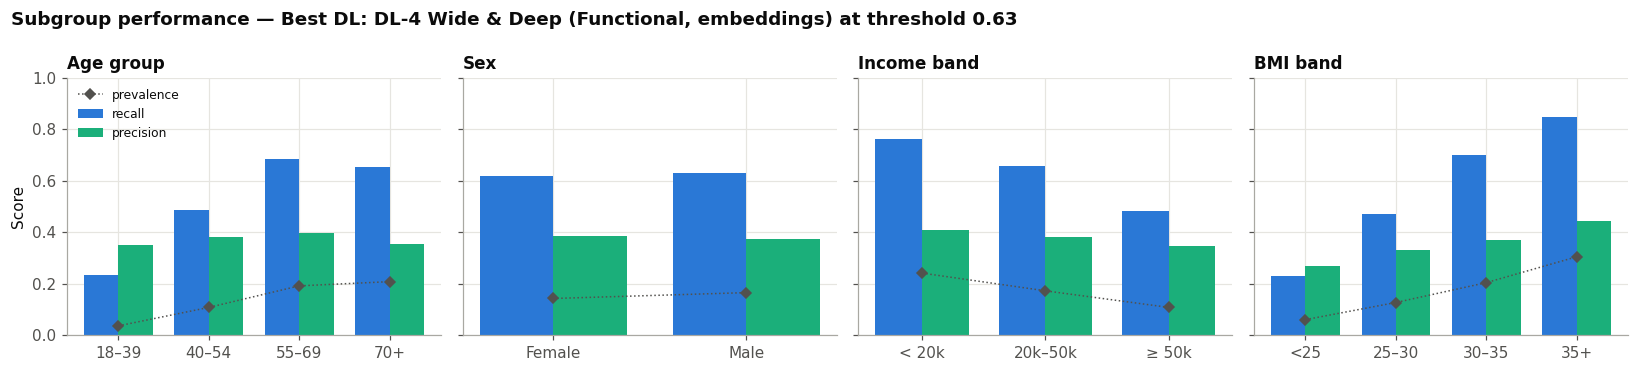

n  prevalence  recall  precision  roc_auc
attribute   level                                                   
Age group   18–39     5122.0       0.037   0.234      0.349    0.857
            40–54     8139.0       0.108   0.485      0.380    0.834
            55–69    12922.0       0.192   0.685      0.399    0.801
            70+       8239.0       0.208   0.652      0.353    0.733
Sex         Female   19235.0       0.143   0.619      0.385    0.826
            Male     15187.0       0.166   0.630      0.373    0.805
Income band < 20k     5718.0       0.241   0.763      0.410    0.774
            20k–50k  12028.0       0.173   0.655      0.381    0.802
            ≥ 50k    16676.0       0.108   0.483      0.345    0.826
BMI band    <25       9236.0       0.061   0.230      0.269    0.812
            25–30    12394.0       0.127   0.472      0.331    0.793
            30–35     7702.0       0.204   0.698      0.369    0.766
            35+       5090.0       0.305   0.848      0.444    0.770

In [40]:
ea["Age group"] = pd.cut(ea["Age"], [0, 4, 7, 10, 13], labels=["18–39", "40–54", "55–69", "70+"])
ea["BMI band"] = pd.cut(ea["BMI"], [0, 25, 30, 35, 200], labels=["<25", "25–30", "30–35", "35+"], right=False)
ea["Income band"] = pd.cut(ea["Income"], [0, 3, 6, 8], labels=["< 20k", "20k–50k", "≥ 50k"])
ea["Sex "] = ea["Sex"].map({0: "Female", 1: "Male"})

def subgroup(g):
    pos = g[g.y == 1]
    return pd.Series({"n": len(g), "prevalence": g.y.mean(), "recall": (pos.pred == 1).mean(),
                      "precision": g.loc[g.pred == 1, "y"].mean(), "roc_auc": roc_auc_score(g.y, g.p)})
groups = ["Age group", "Sex ", "Income band", "BMI band"]
sub = pd.concat({c: ea.groupby(c, observed=True)[["y", "p", "pred"]].apply(subgroup) for c in groups}, names=["attribute", "level"])
sub.to_csv(RESULTS_DIR / "subgroup_performance.csv")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, c in zip(axes, groups):
    s = sub.loc[c]; x = np.arange(len(s)); w = 0.38
    ax.bar(x - w / 2, s["recall"], w, color=PALETTE[0], label="recall")
    ax.bar(x + w / 2, s["precision"], w, color=PALETTE[2], label="precision")
    ax.plot(x, s["prevalence"], color=INK_2, marker="D", ms=5, lw=1, ls=":", label="prevalence")
    ax.set_xticks(x, s.index); ax.set_title(c.strip()); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8, loc="upper left"); axes[0].set_ylabel("Score")
fig.suptitle(f"Subgroup performance — {best_overall} at threshold {t_best:.2f}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "18_subgroup_performance"); plt.show()
sub.round(3)

**Interpretation.** Performance is not uniform. Recall rises steeply with age (≈ 17% for 18–39 vs ≈ 65% for 55–69) and with BMI (≈ 21% for BMI < 25 vs ≈ 81% for BMI ≥ 35). The model has effectively learned that diabetes is a disease of older, heavier people, and it under-detects the minority who do not fit that pattern, such as young-onset or lean diabetes. Interestingly, *ranking* quality (within-group ROC-AUC) is highest in the youngest group (0.86) and lowest in the 70+ group (0.73). In older adults almost everyone carries some risk factors, so the questionnaire has less to discriminate on. Performance by sex is balanced. By income, recall is highest among low-income respondents, where prevalence is also highest. The disparities mostly follow differences in base rate, but a deployment should consider **group-specific thresholds**, or at least monitoring, so that young and lean patients are not systematically missed.

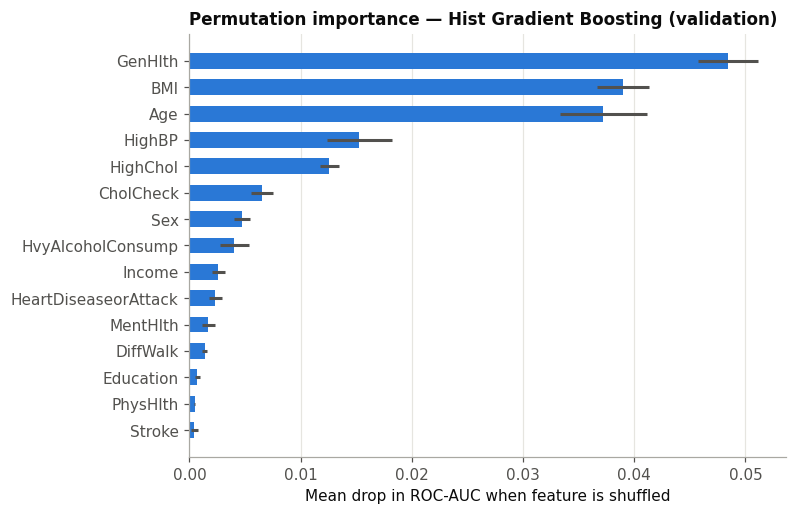

In [41]:
if len(y_val) > 10_000:
    Xs, _, ys, _ = train_test_split(X_val, y_val, train_size=10_000, stratify=y_val, random_state=SEED)
else:
    Xs, ys = X_val, y_val
best_tree = tuned_pipes[best_ml_name]
perm = permutation_importance(best_tree, Xs, ys, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": RAW_FEATURES, "importance": perm.importances_mean, "std": perm.importances_std})
imp = imp.sort_values("importance").tail(15)
imp.to_csv(RESULTS_DIR / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["feature"], imp["importance"], xerr=imp["std"], color=PALETTE[0], height=0.6, ecolor=INK_2)
ax.set_xlabel("Mean drop in ROC-AUC when feature is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title(f"Permutation importance — {best_ml_name} (validation)")
save(fig, "19_permutation_importance"); plt.show()

**Interpretation.** Permutation importance for the best tree model is dominated by three features: **`GenHlth`, `BMI` and `Age`**. Shuffling any one of them costs about 0.04–0.05 ROC-AUC. Next come `HighBP` and `HighChol` (≈ 0.013–0.015). Lifestyle variables (fruit, vegetables, smoking, activity) contribute almost nothing once these are known. This matches clinical risk scores such as FINDRISC and the ADA test, which are built on age, adiposity and blood pressure. The importance of `GenHlth` is a double-edged sword: it is partly a *consequence* of diabetes, not a cause. The model is therefore partly detecting existing, self-perceived illness rather than predicting future risk.

In [42]:
print("Most confident false negatives (diabetic respondents the model scored lowest):")
ea.loc[ea.outcome == "FN"].nsmallest(8, "p")[RAW_FEATURES[:0] + profile_cols + ["p"]].round(3)

Most confident false negatives (diabetic respondents the model scored lowest):


,BMI,Age,GenHlth,HighBP,HighChol,DiffWalk,PhysHlth,Income,HeartDiseaseorAttack,p
199693,29,1,1,0,0,0,0,6,0,0.018
82548,24,5,1,0,0,0,0,4,0,0.019
111187,21,1,2,0,0,0,0,4,0,0.023
59468,27,1,2,0,0,0,0,8,0,0.023
43245,26,3,2,0,0,0,0,6,0,0.025
49039,24,8,1,0,0,0,0,8,0,0.029
27426,21,10,1,0,0,0,0,7,0,0.030
155630,25,6,2,0,1,0,0,8,0,0.032


**Interpretation.** The most confidently missed cases (predicted risk around 2%) report excellent or very good health, normal BMI, no hypertension and no high cholesterol, and several are in the youngest age bands. Nothing in their answers distinguishes them from healthy respondents. These errors are **irreducible with this feature set**: catching them would require laboratory measures (HbA1c, fasting glucose) or family history, which the BRFSS questionnaire does not record.

## 9. Saving the best models and Google Drive artefacts

* **Traditional ML**: the complete scikit-learn `Pipeline` (feature engineering, scaling and model) is saved with `joblib`. It takes raw survey columns as input. Loading it requires `diabetes_features.py` to be importable.
* **Deep learning**: the Keras model is saved in the native `.keras` format, and its fitted preprocessor is saved as a separate `joblib` file.
* `model_card.json` records the chosen thresholds, test metrics and library versions.
* `drive_upload/` collects everything that belongs in the shared Google Drive folder: the zipped raw dataset and both models.

The last cell reloads both models from disk and checks that they reproduce the in-memory predictions.

In [43]:
ml_path = MODEL_DIR / "best_ml_pipeline.joblib"
dl_path = MODEL_DIR / "best_dl_model.keras"
dl_prep_path = MODEL_DIR / ("dl_wide_deep_preprocessor.joblib" if best_dl_is_wd else "dl_preprocessor.joblib")
joblib.dump(best_ml, ml_path, compress=3)
best_dl.save(dl_path)
joblib.dump(wd_prep if best_dl_is_wd else dl_prep, dl_prep_path)
shutil.copy("diabetes_features.py", MODEL_DIR / "diabetes_features.py")

def summary_for(n):
    r = final.query("model == @n and operating_point == 'max_F1 (val)'").iloc[0]
    return {k: round(float(r[k]), 4) for k in ["threshold", "test_roc_auc", "test_pr_auc", "precision", "recall", "f1"]}

card = {"dataset": "CDC Diabetes Health Indicators (UCI id 891), duplicates removed",
        "target": "Diabetes_binary (1 = prediabetes or diabetes)", "input_columns": RAW_FEATURES,
        "best_ml": {"name": best_ml_name, "file": ml_path.name, **summary_for(BEST_ML_KEY),
                    "params": {k: str(v) for k, v in searches[best_ml_name].best_params_.items()}},
        "best_dl": {"name": best_dl_name, "file": dl_path.name, "preprocessor": dl_prep_path.name, **summary_for(BEST_DL_KEY)},
        "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "tensorflow": tf.__version__},
        "seed": SEED, "fast_mode": FAST_MODE}
(MODEL_DIR / "model_card.json").write_text(json.dumps(card, indent=2))

with zipfile.ZipFile(DRIVE_DIR / "cdc_diabetes_health_indicators_raw.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(RAW_CSV, RAW_CSV.name)
for f in MODEL_DIR.iterdir():
    shutil.copy(f, DRIVE_DIR / f.name)
for f in sorted(DRIVE_DIR.iterdir()):
    print(f"{f.name:<45} {f.stat().st_size / 1e6:8.2f} MB")

best_dl_model.keras                               0.28 MB
best_ml_pipeline.joblib                           0.09 MB
cdc_diabetes_health_indicators_raw.zip            2.55 MB
diabetes_features.py                              0.00 MB
dl_wide_deep_preprocessor.joblib                  0.00 MB
model_card.json                                   0.00 MB


In [44]:
reloaded_ml = joblib.load(ml_path)
reloaded_dl = keras.models.load_model(dl_path)
reloaded_prep = joblib.load(dl_prep_path)
sample = X_test.head(500)
ml_ok = np.allclose(reloaded_ml.predict_proba(sample)[:, 1], best_ml.predict_proba(sample)[:, 1])
X_in = to_wd_inputs(sample) if best_dl_is_wd else reloaded_prep.transform(sample).astype("float32")
dl_ok = np.allclose(reloaded_dl.predict(X_in, verbose=0).ravel(), best_dl.predict(X_in, verbose=0).ravel(), atol=1e-6)
print(f"Reloaded ML pipeline reproduces predictions: {ml_ok}")
print(f"Reloaded DL model reproduces predictions:    {dl_ok}")

Reloaded ML pipeline reproduces predictions: True
Reloaded DL model reproduces predictions:    True


**Optional (Colab):** to copy the artefacts straight to Google Drive, uncomment and run the next cell. Then set the folder's sharing to *Anyone with the link can view*.

In [46]:
from google.colab import drive
drive.mount("/content/drive")
shutil.copytree(DRIVE_DIR, "/content/drive/MyDrive/SummativeML_artifacts", dirs_exist_ok=True)

Mounted at /content/drive


'/content/drive/MyDrive/SummativeML_artifacts'

## 10. Conclusions and limitations

**Summary of findings.**
* Using only 21 self-reported survey answers, the best models reach a test **ROC-AUC of about 0.82** for identifying prediabetes or diabetes in 229k de-duplicated respondents. At a screening threshold they catch **about 80% of cases** at around 68% specificity.
* **Traditional ML and deep learning perform equally well.** Tuned Histogram Gradient Boosting and the best Keras networks are statistically indistinguishable (paired bootstrap ΔAUC ≈ 0), and both edge out Logistic Regression by about 0.007 AUC. Gradient boosting reaches this with defaults, trains in about 2 seconds and needs no scaling, so for this tabular problem it is the more practical choice. This agrees with recent benchmarks showing tree ensembles remain the state of the art on medium-sized tabular data (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022).
* **The ceiling comes from the data, not the model.** Learning curves plateau, extra network capacity adds nothing, hyperparameter tuning moves AUC by thousandths, and twelve DL configurations span only 0.004 AUC.
* **Imbalance handling and threshold choice matter more than model choice.** They move recall between 16% and 80% while leaving AUC untouched.

**Limitations.**
1. *Self-report and cross-sectional design.* Diabetes status, BMI and comorbidities are self-reported, and the survey is a snapshot. The model detects **existing, already-diagnosed** disease, together with its consequences (poor general health, difficulty walking), rather than predicting future onset. Some features are therefore plausibly effects rather than causes (reverse causation).
2. *Label noise.* The positive class merges prediabetes with diabetes, and undiagnosed diabetics are labelled negative. Some "false positives" are probably true cases.
3. *Population shift.* The data describe U.S. adults in 2015. The motivating use case, community screening in sub-Saharan Africa, involves different diet, body-composition and age profiles, and evidence suggests BMI thresholds for risk are lower in African populations. The model would need **re-calibration and validation on local data** (for example, Rwanda DHS or STEPS surveys) before any real use.
4. *Calibration.* Class weighting distorts probabilities, so outputs are risk *rankings*, not calibrated risks.
5. *Equity.* Recall is markedly lower for younger and leaner respondents, the groups in which diabetes is more often missed clinically as well.

**Future work.** Add recalibration (isotonic or Platt) and decision-curve analysis to choose a clinically justified threshold; use the 3-class version of the dataset to separate prediabetes from diabetes; and apply SHAP for per-patient explanations. Most importantly, validate on an African cohort.

### References
1. CDC, *Behavioral Risk Factor Surveillance System 2015*; dataset: "CDC Diabetes Health Indicators", UCI Machine Learning Repository, 2023. https://doi.org/10.24432/C53919
2. J. Bergstra and Y. Bengio, "Random search for hyper-parameter optimization," *JMLR*, vol. 13, pp. 281–305, 2012.
3. H.-T. Cheng *et al.*, "Wide & deep learning for recommender systems," in *Proc. 1st Workshop on Deep Learning for Recommender Systems*, 2016.
4. L. Grinsztajn, E. Oyallon and G. Varoquaux, "Why do tree-based models still outperform deep learning on tabular data?" *NeurIPS Datasets and Benchmarks*, 2022.
5. R. Shwartz-Ziv and A. Armon, "Tabular data: Deep learning is not all you need," *Information Fusion*, vol. 81, pp. 84–90, 2022.
6. J. Lindström and J. Tuomilehto, "The diabetes risk score: a practical tool to predict type 2 diabetes risk," *Diabetes Care*, vol. 26, no. 3, pp. 725–731, 2003.
7. Z. Xie *et al.*, "Building risk prediction models for type 2 diabetes using machine learning techniques," *Preventing Chronic Disease*, vol. 16, E130, 2019.